# Multi-asset results (code behind the paper's multi-asset figures)

Run `SP500.ipynb`, `AGG.ipynb` and `USD Index.ipynb` first (their Part 1 exports the position files into `../data/`; the exported files are already included), then run this notebook top to bottom. Figures are written to `figures/`.


In [2]:
import pandas as pd
import numpy as np
import os
FIG_DIR = 'figures/'
os.makedirs(FIG_DIR, exist_ok=True)


In [3]:
SMOOTH_N = 5
_D = '../data/'

def load_positions(folder, stem, asset):
    s = pd.read_excel(f'{_D}{folder}/{stem}_Positions_{SMOOTH_N}s.xlsx')
    r = pd.read_excel(f'{_D}{folder}/{stem}_Positions_raw.xlsx')[['DateTime', f'{asset}_Position']].rename(
        columns={f'{asset}_Position': f'{asset}_Position_raw'})
    return s.merge(r, on='DateTime', how='left')

AGG = load_positions('BBG AGG BOND', 'BBG_AGG', 'BBG AGG BOND')
SP500 = load_positions('SP500', 'SP500', 'SP500')
USD = load_positions('DBUSDX', 'DBUSDX', 'DBUSDX')


In [4]:
_start = max(AGG['DateTime'].min(), SP500['DateTime'].min(), USD['DateTime'].min())
cal = pd.concat([AGG['DateTime'], SP500['DateTime'], USD['DateTime']]).drop_duplicates().sort_values()
cal = pd.DataFrame({'DateTime': cal[(cal >= _start) & (cal <= pd.Timestamp('2025-08-15'))].values})

def _on_calendar(src, cols, ret_col):
    m = cal.merge(src[['DateTime'] + cols], on='DateTime', how='left')
    m.loc[~cal['DateTime'].isin(src['DateTime']).values, ret_col] = 0.0
    return m

df = _on_calendar(AGG, ['BBG AGG BOND_Position', 'BBG AGG BOND_Return', 'BBG AGG BOND_Position_raw'], 'BBG AGG BOND_Return')
df = df.merge(_on_calendar(SP500, ['SP500_Position', 'SP500_Return', 'SP500_Position_raw'], 'SP500_Return'), on='DateTime', how='left')
df = df.merge(_on_calendar(USD, ['DBUSDX_Position', 'DBUSDX_Return', 'DBUSDX_Position_raw'], 'DBUSDX_Return'), on='DateTime', how='left')
_rf = pd.concat([SP500[['DateTime', 'rf_daily']], AGG[['DateTime', 'rf_daily']], USD[['DateTime', 'rf_daily']]]).dropna().drop_duplicates('DateTime')
df = df.merge(_rf, on='DateTime', how='left')

_pos_cols = ['BBG AGG BOND_Position', 'BBG AGG BOND_Position_raw', 'SP500_Position', 'SP500_Position_raw',
             'DBUSDX_Position', 'DBUSDX_Position_raw', 'rf_daily']
df[_pos_cols] = df[_pos_cols].ffill()
df = df[['DateTime' ,'BBG AGG BOND_Position','BBG AGG BOND_Return','BBG AGG BOND_Position_raw',
                   'SP500_Position', 'SP500_Return', 'rf_daily', 'SP500_Position_raw',
                    'DBUSDX_Position', 'DBUSDX_Return', 'DBUSDX_Position_raw']]
df = df.rename(columns={'DBUSDX_Position': 'USD_Position', 'DBUSDX_Return': 'USD_Return', 'DBUSDX_Position_raw': 'USD_Position_raw'})


In [5]:
cost_bps_map = {'SP500': 5, 'BOND': 7, 'USD': 2}

def cash_fill(weighted_ret, active, pos_df, rf=None):
    """EW-style return on days with no active leg: 0 (cash earns nothing) or, if rf is given, the T-bill rate.
    Days where any position is still undefined (signal warm-up) stay 0, as before."""
    out = weighted_ret.copy()
    allout = active.isna()
    out[allout] = 0.0
    if rf is not None:
        defined = allout & pos_df.notna().all(axis=1)
        out[defined] = rf[defined]
    return out

def leg_trades(pos):
    return (pos != pos.shift(1)) & pos.notna() & pos.shift(1).notna()

trades_SP500 = leg_trades(df['SP500_Position'])
trades_BOND = leg_trades(df['BBG AGG BOND_Position'])
trades_USD = leg_trades(df['USD_Position'])


In [6]:
import matplotlib.pyplot as plt
from scipy.stats import skew

def sharpe_ratio(returns, rf_daily=None):
    returns = pd.Series(returns).dropna()
    ann_return = (1 + returns.mean()) ** 252 - 1
    ann_std = returns.std(ddof=1) * np.sqrt(252)
    if rf_daily is not None:
        rf_daily = pd.Series(rf_daily).reindex(returns.index).ffill()
        ann_rf = (1 + rf_daily.mean()) ** 252 - 1
    else:
        ann_rf = 0
    return (ann_return - ann_rf) / ann_std if ann_std != 0 else np.nan

def sortino_ratio(returns):
    returns = pd.Series(returns).dropna()
    downside_std = returns[returns < 0].std(ddof=1)
    return returns.mean() / downside_std * np.sqrt(252) if downside_std != 0 and pd.notna(downside_std) else np.nan

def max_drawdown(cumulative_returns):
    cumulative_returns = pd.Series(cumulative_returns)
    peak = cumulative_returns.cummax()
    drawdown = cumulative_returns / peak - 1
    return drawdown.min()

def skewness(returns):
    return skew(pd.Series(returns).dropna(), nan_policy='omit')

def annualized_return(returns):
    _r = pd.Series(returns).dropna()
    return (1 + _r).prod() ** (252 / len(_r)) - 1 if len(_r) else np.nan

def annualized_vol(returns):
    return pd.Series(returns).dropna().std(ddof=1) * np.sqrt(252)


In [7]:
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.9,
    'axes.grid': True,
    'grid.color': '#999999',
    'grid.alpha': 0.25,
    'grid.linewidth': 0.6,
    'font.size': 11,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'legend.fontsize': 9.5,
    'legend.frameon': False,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'xtick.color': '#333333',
    'ytick.color': '#333333',
})

PALETTE = {
    'SP500': '#2E5C8A', 'BOND': '#2E7D5B', 'USD': '#8A3A4C',
    'benchmark': '#1F77B4', 'strategy': '#C0392B', 'gross': '#8C8C8C', 'gold': '#B8860B',
    'rp': '#5B4B8A', 'vanilla': '#27AE60',
    'bull': None, 'bear': '#B8860B',
    'lookback': {1: '#34495E', 3: '#8E44AD', 5: '#E84393', 7: '#8C8C8C', 9: '#16A085', 10: '#F1C40F', 20: '#C0392B', 30: '#16A085'},
}
STRATEGY_LINE_ALPHA = 0.82

def shade_regime(ax, dates, regime, bear_color=PALETTE['bear'], alpha=0.5):
    """Shade ONLY bearish regime spans in yellow @ alpha=0.5; bullish spans are left unshaded
    (white), not drawn at all, as contiguous runs rather than a per-day loop."""
    dates = pd.to_datetime(pd.Series(dates).reset_index(drop=True))
    regime = pd.Series(regime).reset_index(drop=True)
    valid = regime.notna()
    dates, regime = dates[valid].reset_index(drop=True), regime[valid].reset_index(drop=True)
    if len(regime) == 0:
        return
    block = regime.ne(regime.shift()).cumsum()
    for _, seg in pd.DataFrame({'d': dates, 'r': regime, 'g': block}).groupby('g'):
        if seg['r'].iloc[0] == 0:
            ax.axvspan(seg['d'].iloc[0], seg['d'].iloc[-1], color=bear_color, alpha=alpha, linewidth=0)

def hold_until_n(signal, n):
    """Smoothing standard used everywhere: keep the current state and switch only after the signal has shown
    the opposite value for n consecutive days (entries AND exits). Before the first n-day run the state equals
    the first value; NaN stays NaN. n = 1 returns the signal unchanged."""
    sig = pd.Series(signal).astype(float)
    run = sig.groupby((sig != sig.shift()).cumsum()).cumcount() + 1
    state = sig.where(run >= n).ffill()
    return state.fillna(sig.dropna().iloc[0]).where(sig.notna())

def log_wealth_axis(ax):
    """Log-scale Y axis for cumulative-wealth charts: equal % moves take equal height, but the tick labels
    stay the raw wealth multiple (1, 1.5, 2, ...), not log10 values. Call after the lines are plotted."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_yscale('log')
    lo, hi = ax.get_ylim()
    levels = [(1, 2, 5), (1, 1.5, 2, 3, 5, 7), (1, 1.25, 1.5, 2, 2.5, 3, 4, 5, 6, 8),
              (1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2, 2.25, 2.5, 3, 3.5, 4, 4.5, 5, 6, 7, 8, 9),
              tuple(sorted({1 + 0.05 * k for k in range(20)} | {2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 8.5, 9, 9.5}))]
    best = None
    for mant in levels:
        t = sorted({round(m * 10 ** e, 6) for e in range(-3, 4) for m in mant if lo <= m * 10 ** e <= hi})
        if 5 <= len(t) <= 12 and (best is None or abs(len(t) - 8) < abs(len(best) - 8)): best = t
    if best is None: best = t
    ax.yaxis.set_major_locator(FixedLocator(best))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_locator(NullLocator())


In [8]:
vol_window = 252
df['SP500_Vol']  = df['SP500_Return'].rolling(vol_window).std().shift(1)
df['BOND_Vol'] = df['BBG AGG BOND_Return'].rolling(vol_window).std().shift(1)
df['USD_Vol']  = df['USD_Return'].rolling(vol_window).std().shift(1)

warmup = pd.read_csv(_D + 'vol_warmup_2007.csv', parse_dates=['DateTime'])
for _col in ['SP500_Vol', 'BOND_Vol', 'USD_Vol']:
    df[_col] = df[_col].fillna(df[['DateTime']].merge(warmup[['DateTime', _col]], on='DateTime', how='left')[_col])

inv_vol = 1 / df[['SP500_Vol','BOND_Vol','USD_Vol']]
inv_vol_sum = inv_vol.sum(axis=1)
base_w = inv_vol.div(inv_vol_sum, axis=0)


In [9]:
df['YearMonth'] = df['DateTime'].dt.to_period('M')
_is_rebal = (df['YearMonth'] != df['YearMonth'].shift(1)).values

_spx_r = df['SP500_Return'].values
_bond_r = df['BBG AGG BOND_Return'].values
_usd_r = df['USD_Return'].values
_spx_v = df['SP500_Vol'].values
_bond_v = df['BOND_Vol'].values
_usd_v = df['USD_Vol'].values

def _simulate_monthly_rebalanced(target_fn):
    n = len(df)
    net = np.full(n, np.nan)
    cur_w = None
    for t in range(n):
        r_s, r_b, r_u = _spx_r[t], _bond_r[t], _usd_r[t]
        if np.isnan(r_s) or np.isnan(r_b) or np.isnan(r_u):
            continue
        trade_cost = 0.0
        if _is_rebal[t] or cur_w is None:
            tgt = target_fn(t)
            if tgt is None:
                tgt = cur_w if cur_w is not None else (1/3, 1/3, 1/3)
            if cur_w is not None:
                trade_cost = (
                    abs(tgt[0] - cur_w[0]) * cost_bps_map['SP500']
                    + abs(tgt[1] - cur_w[1]) * cost_bps_map['BOND']
                    + abs(tgt[2] - cur_w[2]) * cost_bps_map['USD']
                ) / 10000
            cur_w = tgt

        r_p = cur_w[0] * r_s + cur_w[1] * r_b + cur_w[2] * r_u
        net[t] = r_p - trade_cost

        denom = 1 + r_p
        cur_w = (
            cur_w[0] * (1 + r_s) / denom,
            cur_w[1] * (1 + r_b) / denom,
            cur_w[2] * (1 + r_u) / denom,
        )
    return net

def _ew_target(t):
    return (1/3, 1/3, 1/3)

def _rp_target(t):
    sv, bv, uv = _spx_v[t], _bond_v[t], _usd_v[t]
    if np.isnan(sv) or np.isnan(bv) or np.isnan(uv):
        return None
    iv = np.array([1/sv, 1/bv, 1/uv])
    iv = iv / iv.sum()
    return tuple(iv)

df['EW_Return'] = _simulate_monthly_rebalanced(_ew_target)
df['RP_Return_nosig'] = _simulate_monthly_rebalanced(_rp_target)
df['EW_CumRet'] = (1 + df['EW_Return'].fillna(0)).cumprod()
df['RP_CumRet_nosig'] = (1 + df['RP_Return_nosig'].fillna(0)).cumprod()

ew_sr = sharpe_ratio(df['EW_Return'], df['rf_daily'])
rp_nosig_sr = sharpe_ratio(df['RP_Return_nosig'], df['rf_daily'])

def _compute_target_path_monthly(target_fn):
    """Same monthly-rebalance-then-buy-and-hold-drift dynamic as _simulate_monthly_rebalanced's
    cur_w, but returns the full daily weight PATH (SP500/BOND/USD columns) instead of the realized
    return. This is the SAA anchor the regime tilt below should deviate from -- IVW's anchor is
    rebalanced at the same monthly cadence as the Vanilla IVW benchmark it's compared against,
    instead of being re-derived from the rolling inverse-vol estimate fresh every single day
    (which silently changed the anchor's own rebalancing frequency at the same time as adding
    the regime signal, confounding the two effects)."""
    n = len(df)
    w_spx = np.full(n, np.nan)
    w_bond = np.full(n, np.nan)
    w_usd = np.full(n, np.nan)
    cur_w = None
    for t in range(n):
        r_s, r_b, r_u = _spx_r[t], _bond_r[t], _usd_r[t]
        if np.isnan(r_s) or np.isnan(r_b) or np.isnan(r_u):
            continue
        if _is_rebal[t] or cur_w is None:
            tgt = target_fn(t)
            if tgt is not None:
                cur_w = tgt
        if cur_w is None:
            continue
        w_spx[t], w_bond[t], w_usd[t] = cur_w
        r_p = cur_w[0] * r_s + cur_w[1] * r_b + cur_w[2] * r_u
        denom = 1 + r_p
        cur_w = (
            cur_w[0] * (1 + r_s) / denom,
            cur_w[1] * (1 + r_b) / denom,
            cur_w[2] * (1 + r_u) / denom,
        )
    return pd.DataFrame({'SP500': w_spx, 'BOND': w_bond, 'USD': w_usd}, index=df.index)

anchor_rp_monthly = _compute_target_path_monthly(_rp_target)


In [10]:
RESMOOTH_ON_COMMON_CALENDAR = True
if RESMOOTH_ON_COMMON_CALENDAR:
    for _p in ['SP500_Position', 'BBG AGG BOND_Position', 'USD_Position']:
        df[_p] = hold_until_n(df[_p + '_raw'].shift(-1), SMOOTH_N).shift(1)

df['DateTime'] = pd.to_datetime(df['DateTime'])

df['SP500_CumRet'] = (1 + df['SP500_Return'].fillna(0)).cumprod()
df['BOND_CumRet'] = (1 + df['BBG AGG BOND_Return'].fillna(0)).cumprod()
df['USD_CumRet'] = (1 + df['USD_Return'].fillna(0)).cumprod()

position_cols = ['SP500_Position', 'BBG AGG BOND_Position', 'USD_Position']
return_cols = ['SP500_Return', 'BBG AGG BOND_Return', 'USD_Return']

df['Active_Assets'] = df[position_cols].sum(axis=1).replace(0, pd.NA)
df['AllOut'] = df['Active_Assets'].isna() & df[position_cols].notna().all(axis=1)

df['Portfolio_Return_raw'] = df.apply(
    lambda row: sum(
        row[pos] * row[ret] for pos, ret in zip(position_cols, return_cols)
    ) / row['Active_Assets'] if pd.notna(row['Active_Assets'])
    else (row['rf_daily'] if row['AllOut'] else 0),
    axis=1
)

def _leg_weight(pos_col):
    pos = df[pos_col].fillna(0)
    return (pos / df['Active_Assets']).fillna(0)

w_spx_daily = _leg_weight('SP500_Position')
w_bond_daily = _leg_weight('BBG AGG BOND_Position')
w_usd_daily = _leg_weight('USD_Position')

Portfolio_cost_drag = (
    (w_spx_daily - w_spx_daily.shift(1)).abs().fillna(0) * (cost_bps_map['SP500'] / 10000)
    + (w_bond_daily - w_bond_daily.shift(1)).abs().fillna(0) * (cost_bps_map['BOND'] / 10000)
    + (w_usd_daily - w_usd_daily.shift(1)).abs().fillna(0) * (cost_bps_map['USD'] / 10000)
)
df['Portfolio_Return'] = df['Portfolio_Return_raw'] - Portfolio_cost_drag
df['Portfolio_Return_cash0'] = df['Portfolio_Return'] - df['AllOut'].astype(float) * df['rf_daily'].fillna(0)
df['Portfolio_CumRet'] = (1 + df['Portfolio_Return'].fillna(0)).cumprod()

spx_sr  = sharpe_ratio(df['SP500_Return'], df["rf_daily"])
bond_sr = sharpe_ratio(df['BBG AGG BOND_Return'], df["rf_daily"])
usd_sr  = sharpe_ratio(df['USD_Return'], df["rf_daily"])
port_sr = sharpe_ratio(df['Portfolio_Return'], df["rf_daily"])


/var/folders/hk/ysvf16597_13lb0mk93zgbsc0000gn/T/ipykernel_81240/1580037570.py:28: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return (pos / df['Active_Assets']).fillna(0)


## Figure: equal-weight portfolio with the regime signal vs vanilla EW (`EW_with_SP500.png`)


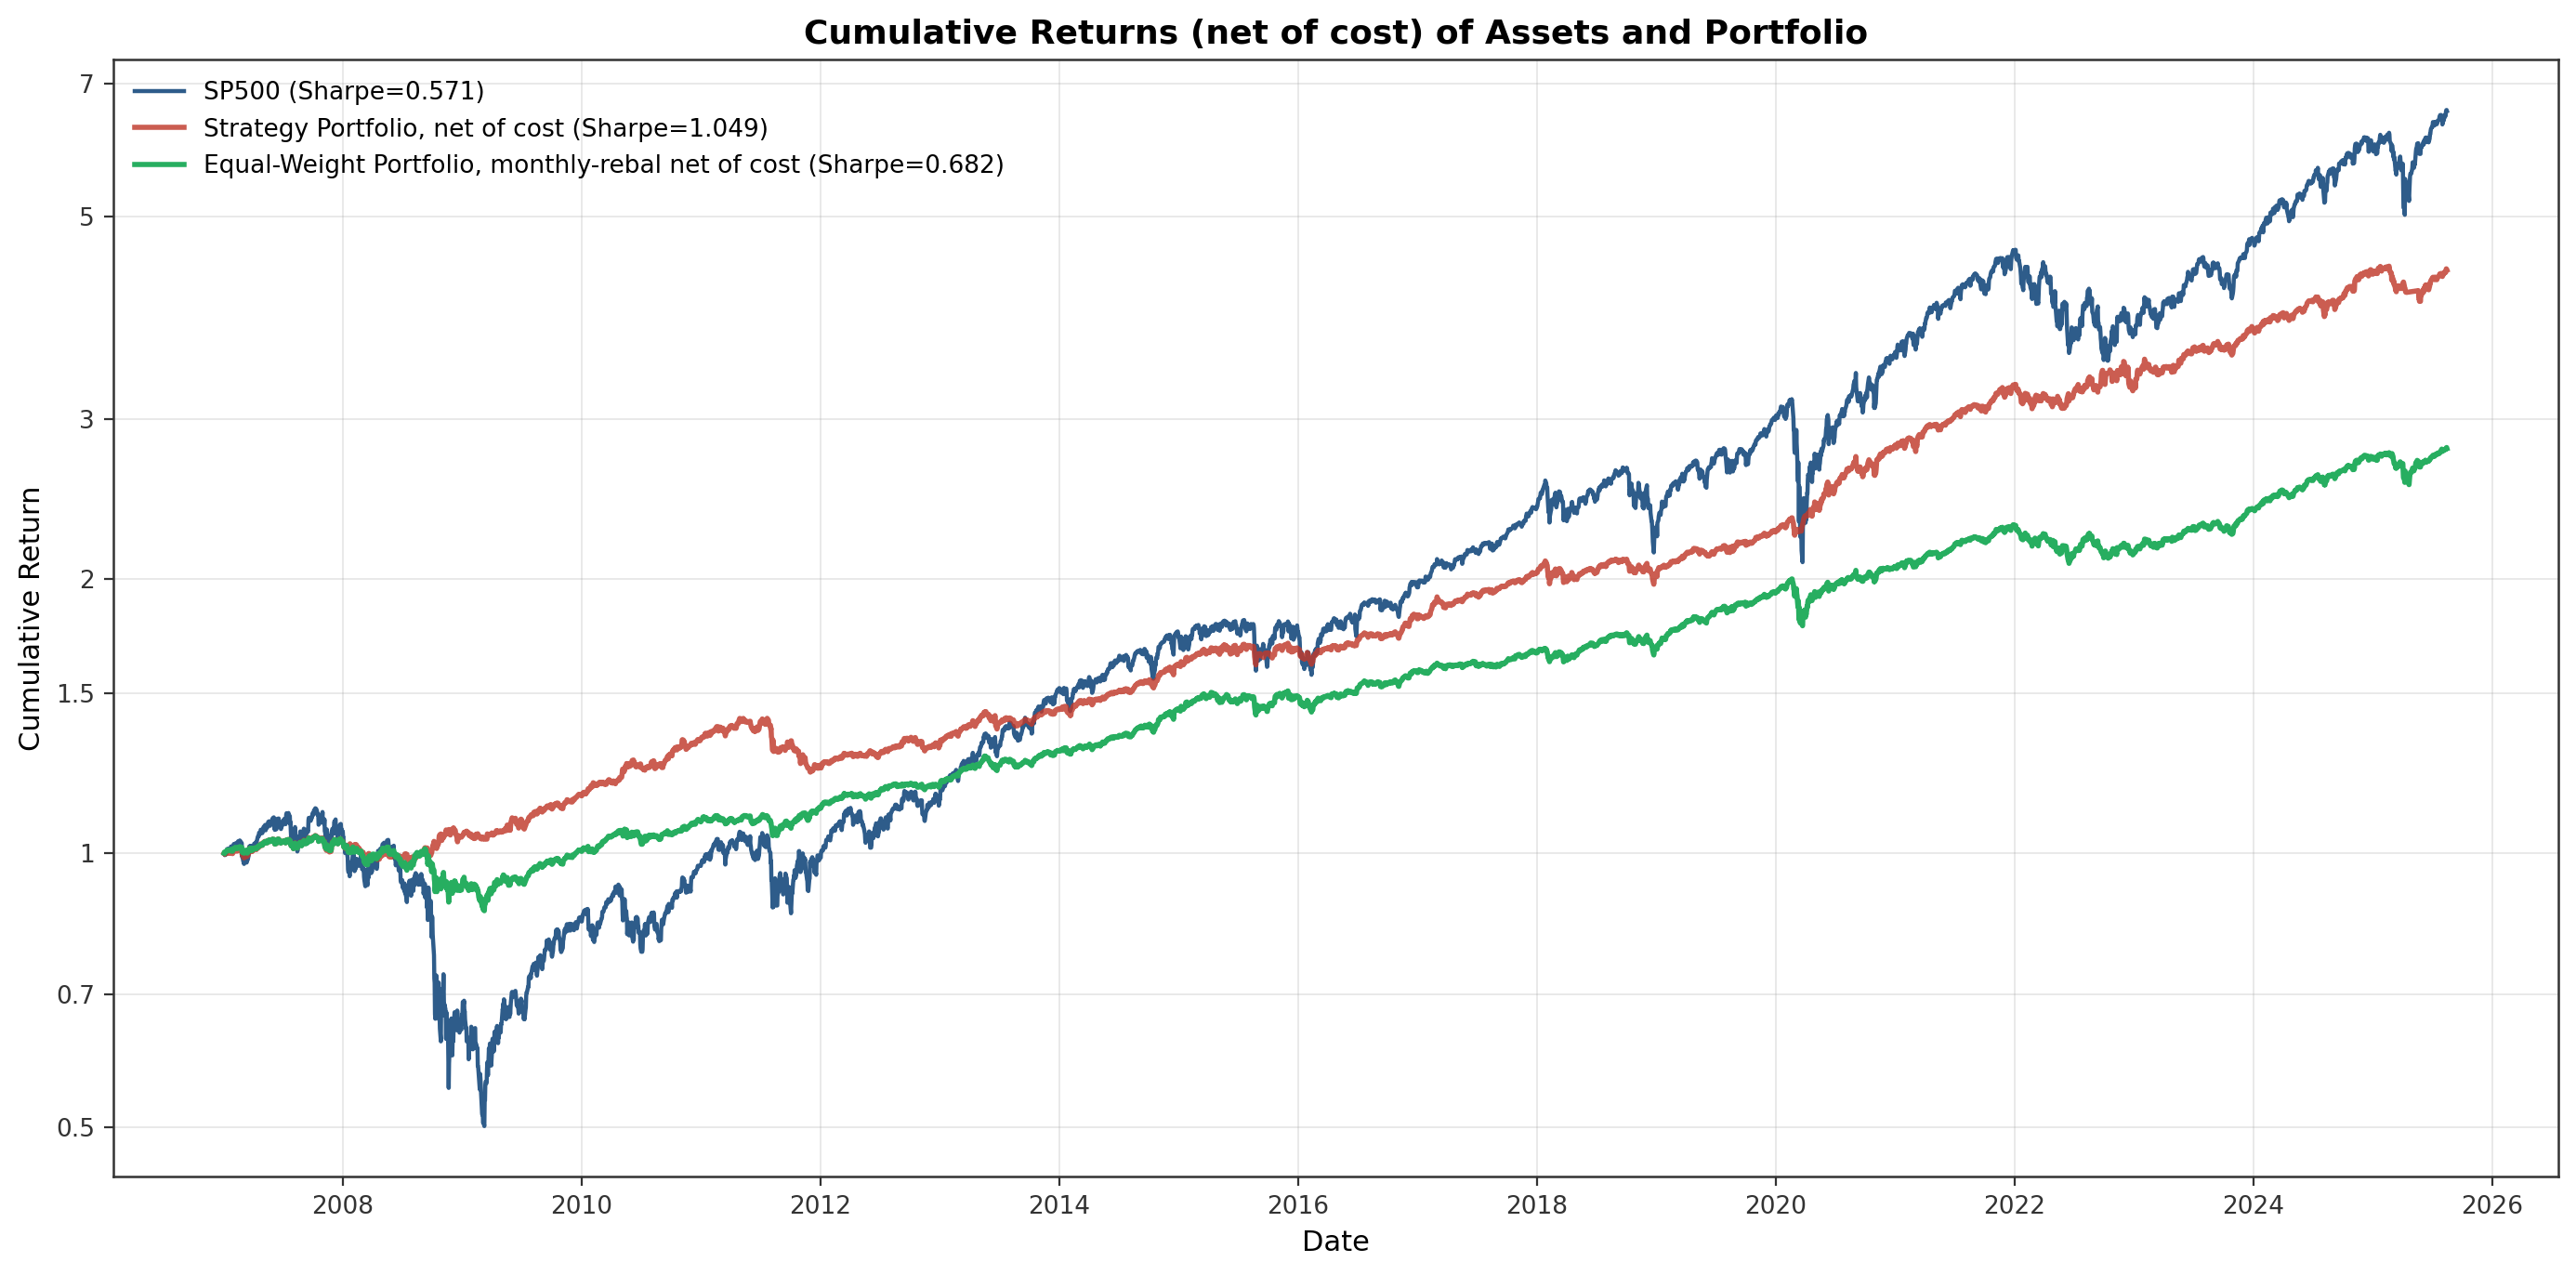

In [11]:
spx_sr_own = sharpe_ratio(SP500.loc[SP500['DateTime'] <= '2025-08-15', 'SP500_Return'], SP500.loc[SP500['DateTime'] <= '2025-08-15', 'rf_daily'])
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(df['DateTime'].values, df['SP500_CumRet'].values, label=f'SP500 (Sharpe={spx_sr_own:.3f})', color=PALETTE['SP500'], linewidth=1.6)
ax.plot(df['DateTime'].values, df['Portfolio_CumRet'].values, label=f'Strategy Portfolio, net of cost (Sharpe={port_sr:.3f})', color=PALETTE['strategy'], alpha=STRATEGY_LINE_ALPHA, linewidth=2)
ax.plot(df['DateTime'].values, df['EW_CumRet'].values, label=f'Equal-Weight Portfolio, monthly-rebal net of cost (Sharpe={ew_sr:.3f})', color=PALETTE['vanilla'], linewidth=2)

ax.set_title('Cumulative Returns (net of cost) of Assets and Portfolio')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return')
log_wealth_axis(ax)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + 'EW_with_SP500.png', dpi=200, bbox_inches='tight')
plt.show()


In [12]:
df['w_SP500']  = anchor_rp_monthly['SP500']  * df['SP500_Position']
df['w_BOND'] = anchor_rp_monthly['BOND'] * df['BBG AGG BOND_Position']
df['w_USD']  = anchor_rp_monthly['USD']  * df['USD_Position']

weight_total = df[['w_SP500','w_BOND','w_USD']].sum(axis=1)
df.loc[weight_total != 0, 'w_SP500']  /= weight_total[weight_total != 0]
df.loc[weight_total != 0, 'w_BOND'] /= weight_total[weight_total != 0]
df.loc[weight_total != 0, 'w_USD']  /= weight_total[weight_total != 0]

df['RP_Return_raw'] = (
    df['w_SP500']  * df['SP500_Return'] +
    df['w_BOND'] * df['BBG AGG BOND_Return'] +
    df['w_USD']  * df['USD_Return']
)

RP_cost_drag = (
    (df['w_SP500'] - df['w_SP500'].shift(1)).abs().fillna(0) * (cost_bps_map['SP500'] / 10000)
    + (df['w_BOND'] - df['w_BOND'].shift(1)).abs().fillna(0) * (cost_bps_map['BOND'] / 10000)
    + (df['w_USD'] - df['w_USD'].shift(1)).abs().fillna(0) * (cost_bps_map['USD'] / 10000)
)
df['RP_Return_raw'] = df['RP_Return_raw'] + df['AllOut'].astype(float) * df['rf_daily'].fillna(0)
df['RP_Return'] = df['RP_Return_raw'] - RP_cost_drag
df['RP_Return_cash0'] = df['RP_Return'] - df['AllOut'].astype(float) * df['rf_daily'].fillna(0)
df['RP_CumRet'] = (1 + df['RP_Return'].fillna(0)).cumprod()

rp_sr = sharpe_ratio(df['RP_Return'], df['rf_daily'])


## Figure: inverse-volatility-weighted portfolio with the regime signal vs vanilla IVW (`RP_with_SP500.png`)


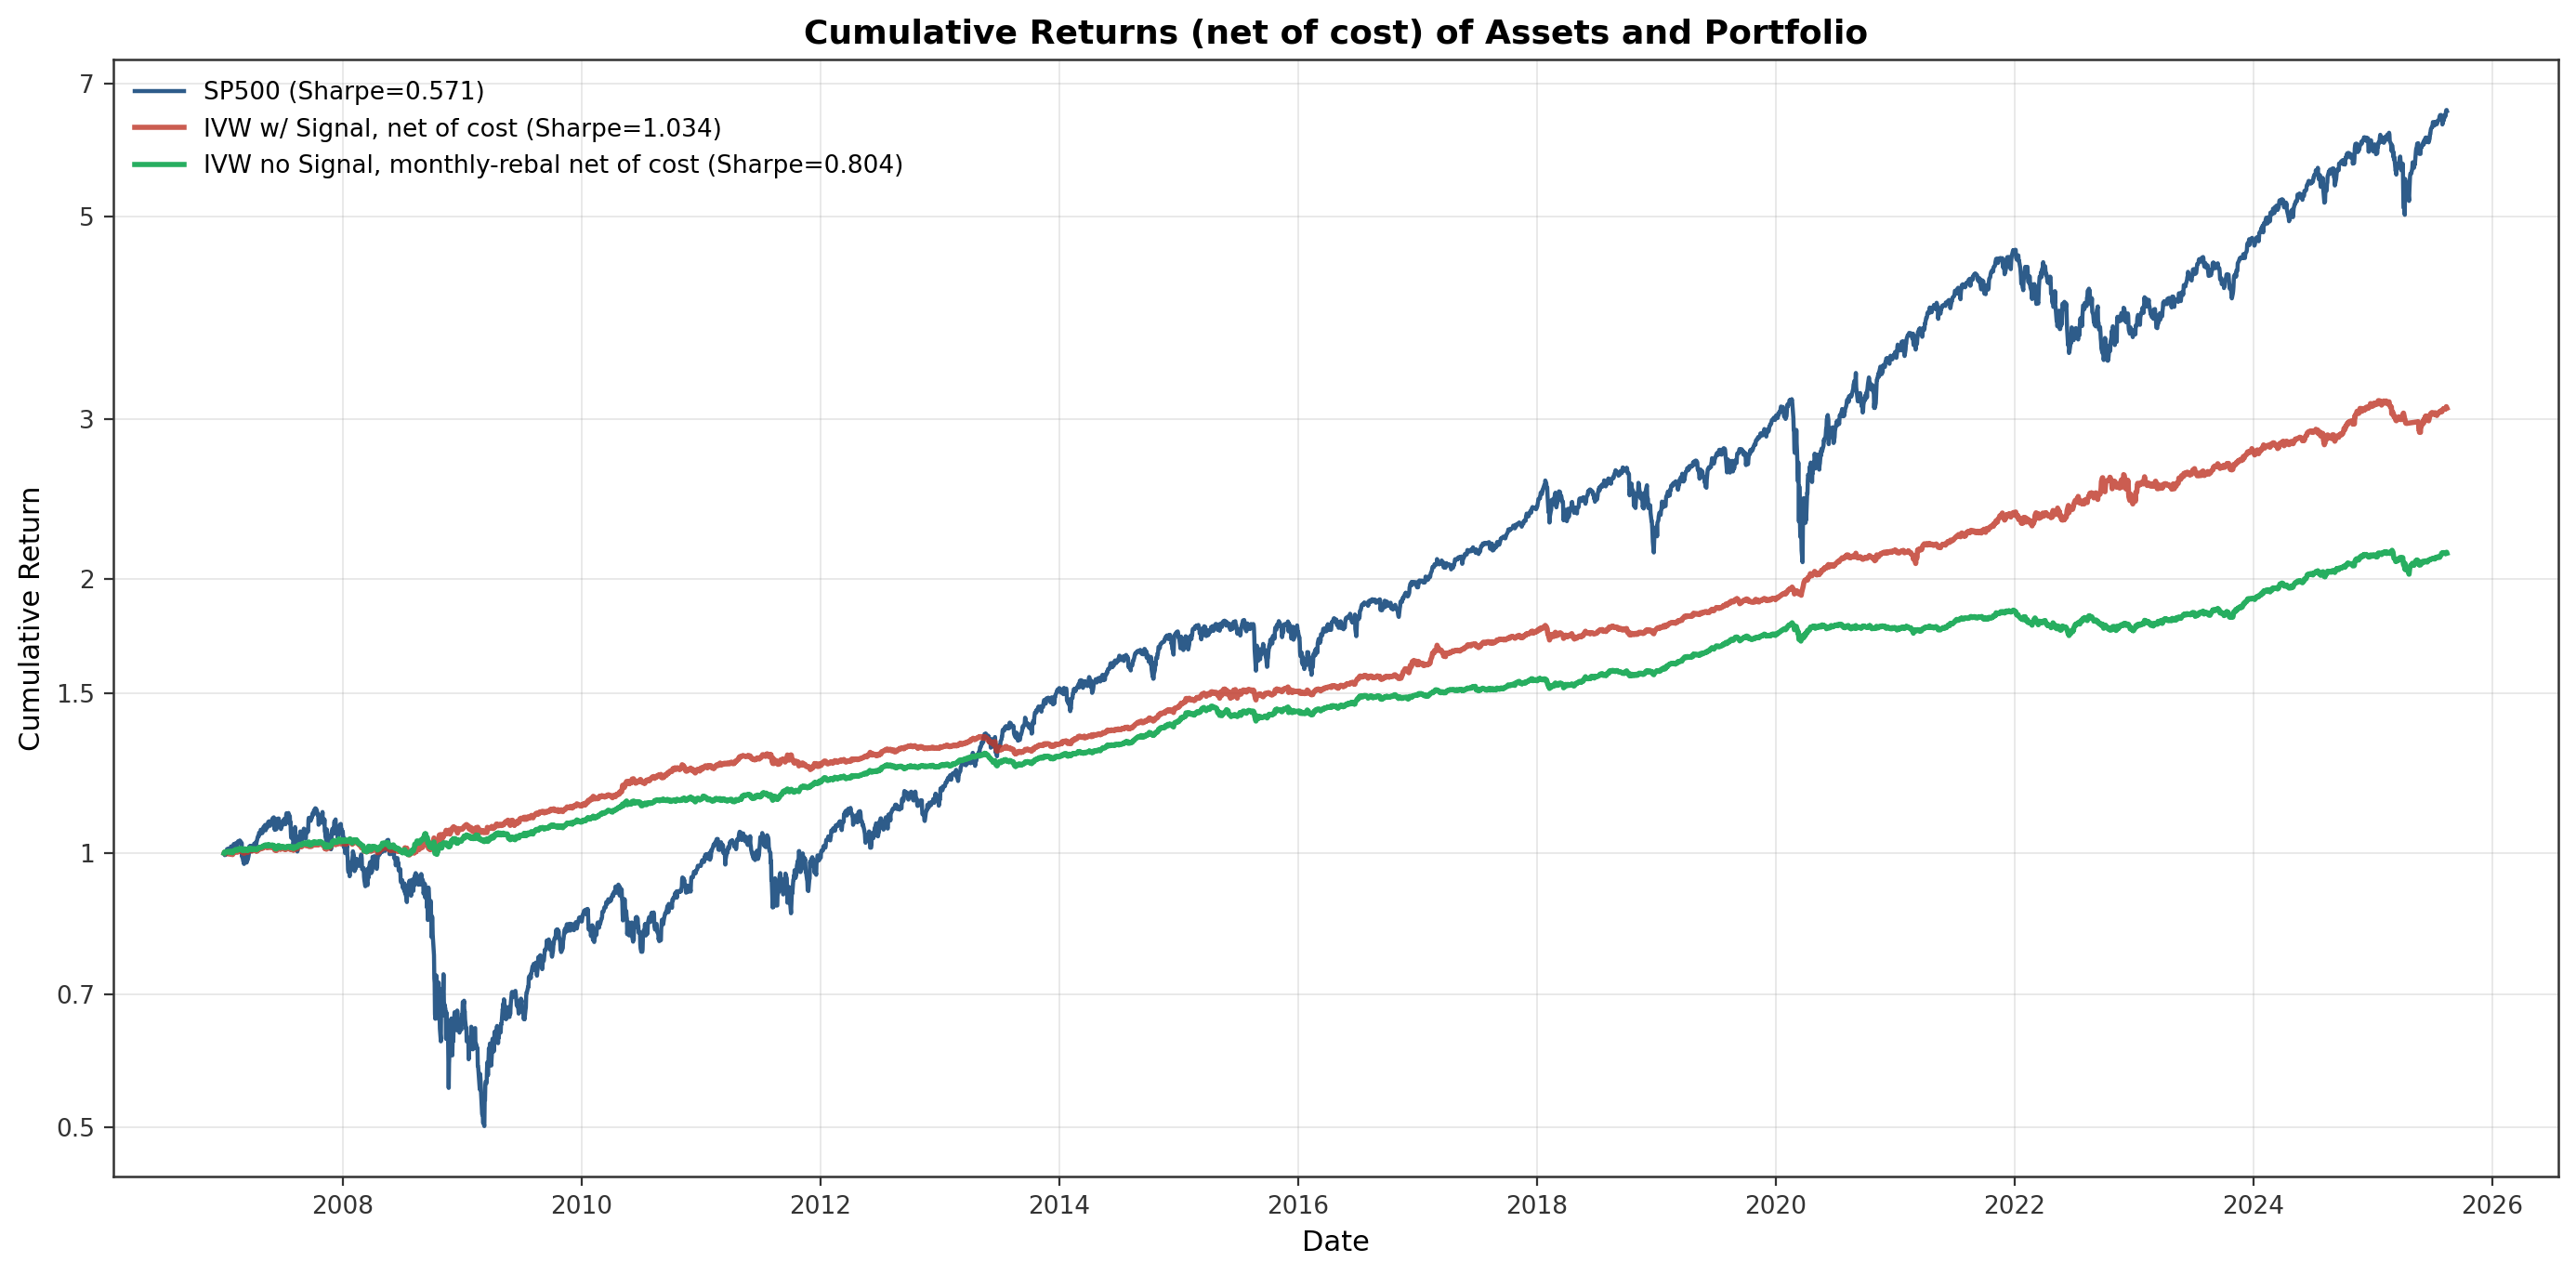

In [13]:
fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(df['DateTime'].values, df['SP500_CumRet'].values,  label=f'SP500 (Sharpe={spx_sr_own:.3f})', color=PALETTE['SP500'], linewidth=1.6)
ax.plot(df['DateTime'].values, df['RP_CumRet'].values,   label=f'IVW w/ Signal, net of cost (Sharpe={rp_sr:.3f})',  color=PALETTE['strategy'], alpha=STRATEGY_LINE_ALPHA, linewidth=2)
ax.plot(df['DateTime'].values, df['RP_CumRet_nosig'].values, label=f'IVW no Signal, monthly-rebal net of cost (Sharpe={rp_nosig_sr:.3f})', color=PALETTE['vanilla'], linewidth=2)

ax.set_title('Cumulative Returns (net of cost) of Assets and Portfolio')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return')
log_wealth_axis(ax)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR + 'RP_with_SP500.png', dpi=200, bbox_inches='tight')
plt.show()


In [14]:
df["SP500_01_Return_cash0"] = df["SP500_Position"] * df["SP500_Return"] - trades_SP500.astype(float) * (cost_bps_map['SP500'] / 10000)
df["SP500_01_Return"] = df["SP500_Position"] * df["SP500_Return"] + (1 - df["SP500_Position"]) * df["rf_daily"] - trades_SP500.astype(float) * (cost_bps_map['SP500'] / 10000)
df["SP500_01_CumRet"] = (1 + df["SP500_01_Return"].fillna(0)).cumprod()

df["USD_01_Return_cash0"] = df["USD_Position"] * df["USD_Return"] - trades_USD.astype(float) * (cost_bps_map['USD'] / 10000)
df["USD_01_Return"] = df["USD_Position"] * df["USD_Return"] + (1 - df["USD_Position"]) * df["rf_daily"] - trades_USD.astype(float) * (cost_bps_map['USD'] / 10000)
df["USD_01_CumRet"] = (1 + df["USD_01_Return"].fillna(0)).cumprod()

df["AGG_01_Return_cash0"] = df["BBG AGG BOND_Position"] * df["BBG AGG BOND_Return"] - trades_BOND.astype(float) * (cost_bps_map['BOND'] / 10000)
df["AGG_01_Return"] = df["BBG AGG BOND_Position"] * df["BBG AGG BOND_Return"] + (1 - df["BBG AGG BOND_Position"]) * df["rf_daily"] - trades_BOND.astype(float) * (cost_bps_map['BOND'] / 10000)
df["AGG_01_CumRet"] = (1 + df["AGG_01_Return"].fillna(0)).cumprod()


## Rolling one-year cumulative returns (helper)


In [15]:
sp500_days = np.flatnonzero(df['DateTime'].isin(SP500['DateTime']).values)

def rolling_cumret(returns, window=252, step=21):
    """One-year rolling cumulative return: each window spans `window` S&P 500 trading days, stepped by `step` of them."""
    cumrets = []
    dates = []
    for start in range(0, len(sp500_days) - window + 1, step):
        first, last = sp500_days[start], sp500_days[start + window - 1]
        cumrets.append((1 + returns.iloc[first:last + 1].fillna(0)).prod() - 1)
        dates.append(df["DateTime"].iloc[last])
    return pd.Series(cumrets, index=dates)


## Figure: rolling one-year cumulative returns, single assets and EW / IVW portfolios (`rolling_cumret.png`)


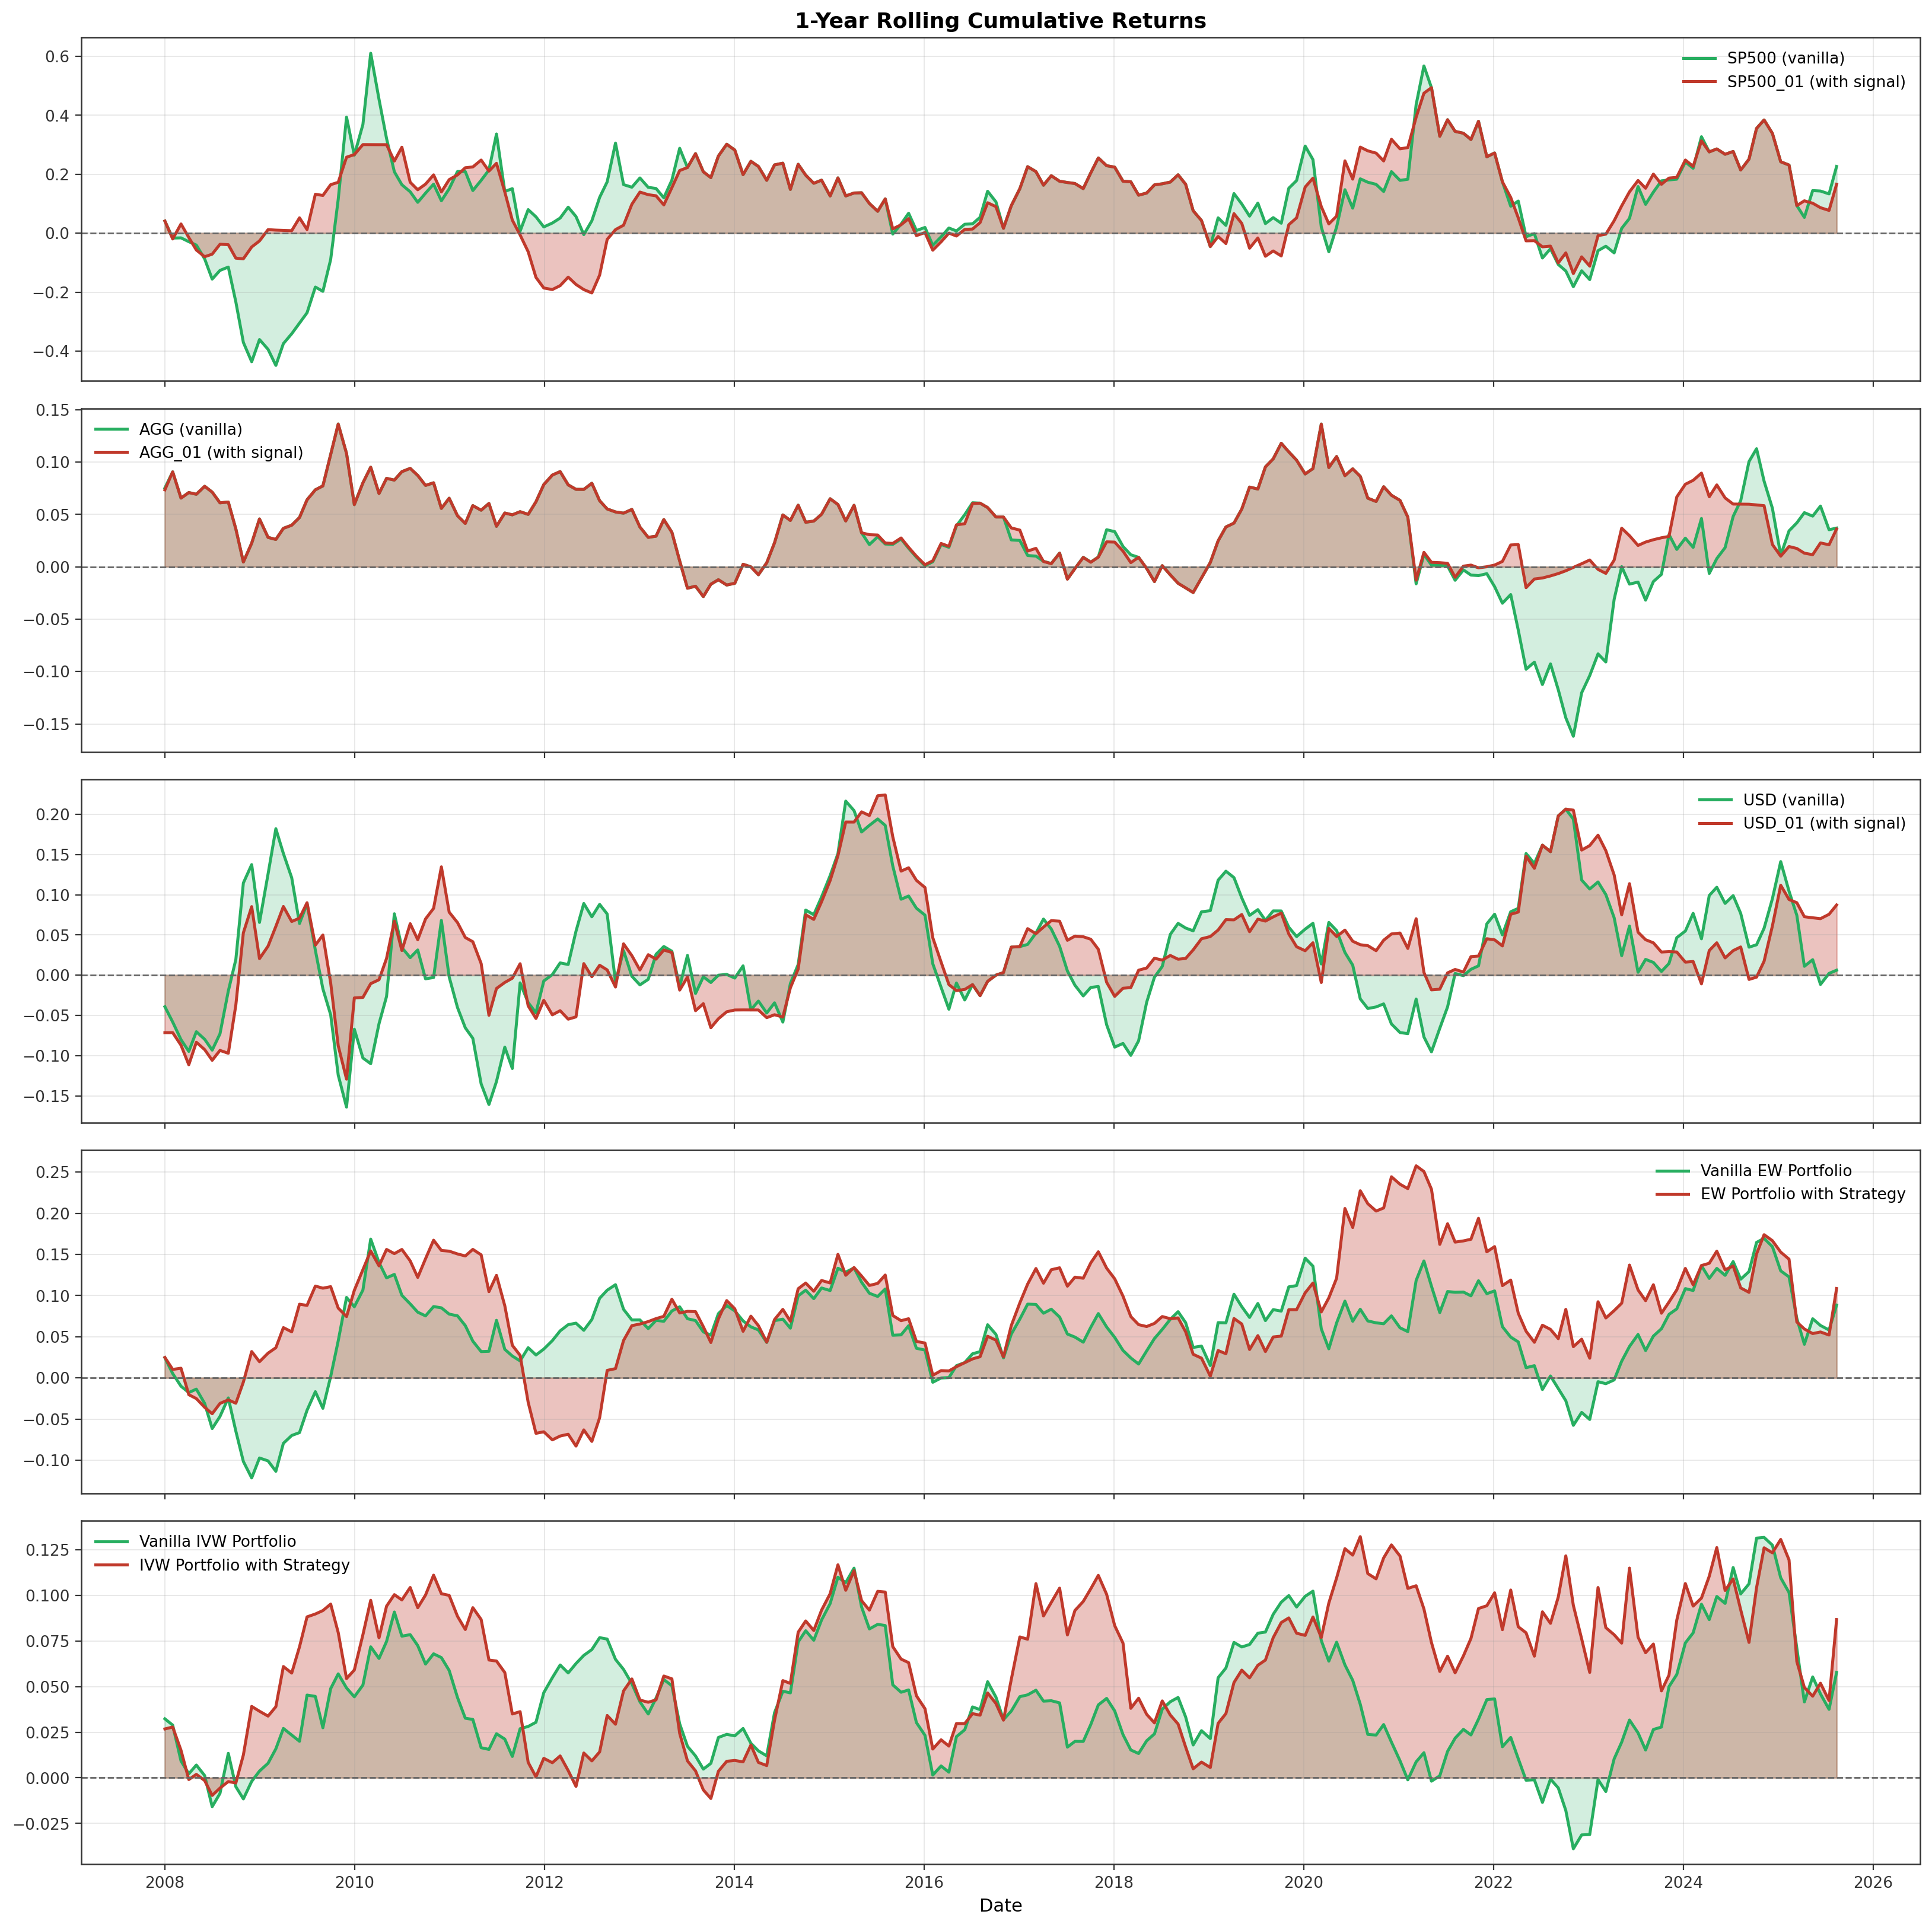

In [16]:
fig, axes = plt.subplots(5, 1, figsize=(20, 20), sharex=True,
                          gridspec_kw={"hspace": 0.08})

ax = axes[0]
s = rolling_cumret(df["SP500_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['vanilla'], alpha=0.2)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['vanilla'], linewidth=1.8, label="SP500 (vanilla)")
s = rolling_cumret(df["SP500_01_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['strategy'], alpha=0.30)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['strategy'], linewidth=1.8, label="SP500_01 (with signal)")
ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
ax.set_title("1-Year Rolling Cumulative Returns")
ax.legend()

ax = axes[1]
s = rolling_cumret(df["BBG AGG BOND_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['vanilla'], alpha=0.2)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['vanilla'], linewidth=1.8, label="AGG (vanilla)")
s = rolling_cumret(df["AGG_01_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['strategy'], alpha=0.30)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['strategy'], linewidth=1.8, label="AGG_01 (with signal)")
ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
ax.legend()

ax = axes[2]
s = rolling_cumret(df["USD_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['vanilla'], alpha=0.2)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['vanilla'], linewidth=1.8, label="USD (vanilla)")
s = rolling_cumret(df["USD_01_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['strategy'], alpha=0.30)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['strategy'], linewidth=1.8, label="USD_01 (with signal)")
ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
ax.legend()

ax = axes[3]
s = rolling_cumret(df["EW_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['vanilla'], alpha=0.2)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['vanilla'], linewidth=1.8, label="Vanilla EW Portfolio")
s = rolling_cumret(df["Portfolio_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['strategy'], alpha=0.30)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['strategy'], linewidth=1.8, label="EW Portfolio with Strategy")
ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
ax.legend()

ax = axes[4]
s = rolling_cumret(df["RP_Return_nosig"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['vanilla'], alpha=0.2)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['vanilla'], linewidth=1.8, label="Vanilla IVW Portfolio")
s = rolling_cumret(df["RP_Return"])
ax.fill_between(s.index.to_numpy(), 0, s.values.flatten(), color=PALETTE['strategy'], alpha=0.30)
ax.plot(s.index.to_numpy(), s.values.flatten(), color=PALETTE['strategy'], linewidth=1.8, label="IVW Portfolio with Strategy")
ax.axhline(0, color="#666666", linestyle="--", linewidth=1)
ax.set_xlabel("Date")
ax.legend()

for ax in axes:
    ax.label_outer()

plt.savefig(FIG_DIR + 'rolling_cumret.png', dpi=150, bbox_inches='tight')
plt.show()


## Holding-period extension: lookback confirmation (computation)


In [17]:
df['SP500_Signal_raw'] = df['SP500_Position_raw'].shift(-1)
df['BOND_Signal_raw'] = df['BBG AGG BOND_Position_raw'].shift(-1)
df['USD_Signal_raw'] = df['USD_Position_raw'].shift(-1)

LOOKBACK_THRESH = 0.8
lookback_list = [10, 20, 30]
lookback_list_all = [1] + lookback_list

def lookback_name(lb):
    return 'Main result' if lb == 1 else f'N={lb}'

def smooth_position(raw_signal, lb):
    main = hold_until_n(raw_signal, SMOOTH_N)
    if lb == 1:
        return main.shift(1)
    share = main.rolling(lb).mean()
    return (share >= LOOKBACK_THRESH - 1e-12).astype(float).where(share.notna()).shift(1)

_OWN = {'SP500': (SP500, 'SP500_Return', 'SP500_Position_raw'),
        'BOND':  (AGG,   'BBG AGG BOND_Return', 'BBG AGG BOND_Position_raw'),
        'USD':   (USD,   'DBUSDX_Return', 'DBUSDX_Position_raw')}

def own_benchmark(leg):
    frame, ret_col, _ = _OWN[leg]
    f = frame[frame['DateTime'] <= pd.Timestamp('2025-08-15')].reset_index(drop=True)
    return f['DateTime'], f[ret_col], f['rf_daily']

def own_calendar_asset(leg, lb, cost_bps):
    """Net-of-cost return of one leg on its own calendar: (dates, net return, rf)."""
    frame, ret_col, raw_col = _OWN[leg]
    f = frame[frame['DateTime'] <= pd.Timestamp('2025-08-15')].reset_index(drop=True)
    main = hold_until_n(f[raw_col], SMOOTH_N)
    if lb == 1:
        pos = main
    else:
        share = main.rolling(lb).mean()
        pos = (share >= LOOKBACK_THRESH - 1e-12).astype(float).where(share.notna())
    trades = (pos != pos.shift(1)) & pos.notna() & pos.shift(1).notna()
    ret = pos * f[ret_col] + (1 - pos) * f['rf_daily'] - trades.astype(float) * (cost_bps / 10000)
    return f['DateTime'], ret, f['rf_daily']

def rp_weights_for_lookback(spx_pos, bond_pos, usd_pos):
    w_spx  = (anchor_rp_monthly['SP500']  * spx_pos).copy()
    w_bond = (anchor_rp_monthly['BOND'] * bond_pos).copy()
    w_usd  = (anchor_rp_monthly['USD']  * usd_pos).copy()
    w_total = w_spx + w_bond + w_usd
    nz = w_total != 0
    w_spx[nz]  = w_spx[nz]  / w_total[nz]
    w_bond[nz] = w_bond[nz] / w_total[nz]
    w_usd[nz]  = w_usd[nz]  / w_total[nz]
    return w_spx, w_bond, w_usd

lookback_summary_rows = []
lb_series = {}

for lb in lookback_list_all:
    spx_pos = smooth_position(df['SP500_Signal_raw'], lb)
    bond_pos = smooth_position(df['BOND_Signal_raw'], lb)
    usd_pos = smooth_position(df['USD_Signal_raw'], lb)

    pos_df = pd.DataFrame({'SP500': spx_pos, 'BOND': bond_pos, 'USD': usd_pos})
    ret_df = pd.DataFrame({'SP500': df['SP500_Return'], 'BOND': df['BBG AGG BOND_Return'], 'USD': df['USD_Return']})

    active = pos_df.sum(axis=1).replace(0, np.nan)
    weighted_num = pos_df['SP500'] * ret_df['SP500'] + pos_df['BOND'] * ret_df['BOND'] + pos_df['USD'] * ret_df['USD']
    weighted_ret = weighted_num / active

    port_ret_raw = cash_fill(weighted_ret, active, pos_df, df['rf_daily'])

    trades = {}
    for label, pos in [('SP500', spx_pos), ('BOND', bond_pos), ('USD', usd_pos)]:
        trades[label] = (pos != pos.shift(1)) & pos.notna() & pos.shift(1).notna()

    spx_ret = spx_pos * df['SP500_Return'] + (1 - spx_pos) * df['rf_daily'] - trades['SP500'].astype(float) * (cost_bps_map['SP500'] / 10000)
    bond_ret = bond_pos * df['BBG AGG BOND_Return'] + (1 - bond_pos) * df['rf_daily'] - trades['BOND'].astype(float) * (cost_bps_map['BOND'] / 10000)
    usd_ret = usd_pos * df['USD_Return'] + (1 - usd_pos) * df['rf_daily'] - trades['USD'].astype(float) * (cost_bps_map['USD'] / 10000)
    own = {leg: own_calendar_asset(leg, lb, cost_bps_map[leg]) for leg in ['SP500', 'BOND', 'USD']}
    spx_cum = (1 + own['SP500'][1].fillna(0)).cumprod()
    bond_cum = (1 + own['BOND'][1].fillna(0)).cumprod()
    usd_cum = (1 + own['USD'][1].fillna(0)).cumprod()

    w_ew = {a: (pos_df[a].fillna(0) / active).fillna(0) for a in ['SP500', 'BOND', 'USD']}
    cost_drag = sum(
        (w_ew[a] - w_ew[a].shift(1)).abs().fillna(0) * (cost_bps_map[a] / 10000)
        for a in ['SP500', 'BOND', 'USD']
    )
    port_ret = port_ret_raw - cost_drag
    port_cum = (1 + port_ret.fillna(0)).cumprod()

    w_spx_lb, w_bond_lb, w_usd_lb = rp_weights_for_lookback(spx_pos, bond_pos, usd_pos)
    rp_cash = (active.isna() & pos_df.notna().all(axis=1)).astype(float) * df['rf_daily'].fillna(0)
    rp_ret_raw = (w_spx_lb * df['SP500_Return'] + w_bond_lb * df['BBG AGG BOND_Return'] + w_usd_lb * df['USD_Return']) + rp_cash
    rp_cost_drag = (
        (w_spx_lb - w_spx_lb.shift(1)).abs().fillna(0)  * (cost_bps_map['SP500'] / 10000)
        + (w_bond_lb - w_bond_lb.shift(1)).abs().fillna(0) * (cost_bps_map['BOND'] / 10000)
        + (w_usd_lb - w_usd_lb.shift(1)).abs().fillna(0)  * (cost_bps_map['USD'] / 10000)
    )
    rp_ret = rp_ret_raw - rp_cost_drag
    rp_cum = (1 + rp_ret.fillna(0)).cumprod()

    lookback_summary_rows.append({
        'Lookback': lb,
        'EW+Sig AnnRet': annualized_return(port_ret),
        'EW+Sig Sharpe': sharpe_ratio(port_ret, df['rf_daily']),
        'EW+Sig Sortino': sortino_ratio(port_ret),
        'EW+Sig MaxDD': max_drawdown(port_cum),
        'IVW AnnRet': annualized_return(rp_ret),
        'IVW Sharpe': sharpe_ratio(rp_ret, df['rf_daily']),
        'IVW Sortino': sortino_ratio(rp_ret),
        'IVW MaxDD': max_drawdown(rp_cum),
        'SP500 Sharpe': sharpe_ratio(own['SP500'][1], own['SP500'][2]),
        'BOND Sharpe': sharpe_ratio(own['BOND'][1], own['BOND'][2]),
        'USD Sharpe': sharpe_ratio(own['USD'][1], own['USD'][2]),
    })
    lb_series[lb] = {
        'port_cum': port_cum, 'rp_cum': rp_cum,
        'spx_cum': spx_cum, 'bond_cum': bond_cum, 'usd_cum': usd_cum,
        'spx_dt': own['SP500'][0], 'bond_dt': own['BOND'][0], 'usd_dt': own['USD'][0],
    }

lookback_summary_df = pd.DataFrame(lookback_summary_rows).set_index('Lookback')
lookback_summary_df.round(4)


,EW+Sig AnnRet,EW+Sig Sharpe,EW+Sig Sortino,EW+Sig MaxDD,IVW AnnRet,IVW Sharpe,IVW Sortino,IVW MaxDD,SP500 Sharpe,BOND Sharpe,USD Sharpe
Lookback,,,,,,,,,,,
1,0.0805,1.0492,1.5635,-0.1272,0.0609,1.0337,1.7293,-0.0771,0.8484,0.7051,0.3144
10,0.0779,0.9837,1.4523,-0.0984,0.0579,0.9240,1.4842,-0.0799,0.8181,0.7677,0.2854
20,0.0784,0.9765,1.4432,-0.0781,0.0586,0.9028,1.4413,-0.0768,0.8021,0.7613,0.2687
30,0.0722,0.8750,1.2883,-0.1236,0.0543,0.7970,1.2724,-0.1195,0.7466,0.7885,0.1658


## Figure: single-asset 0/1 strategies by lookback window (`lb_single_asset.png`)


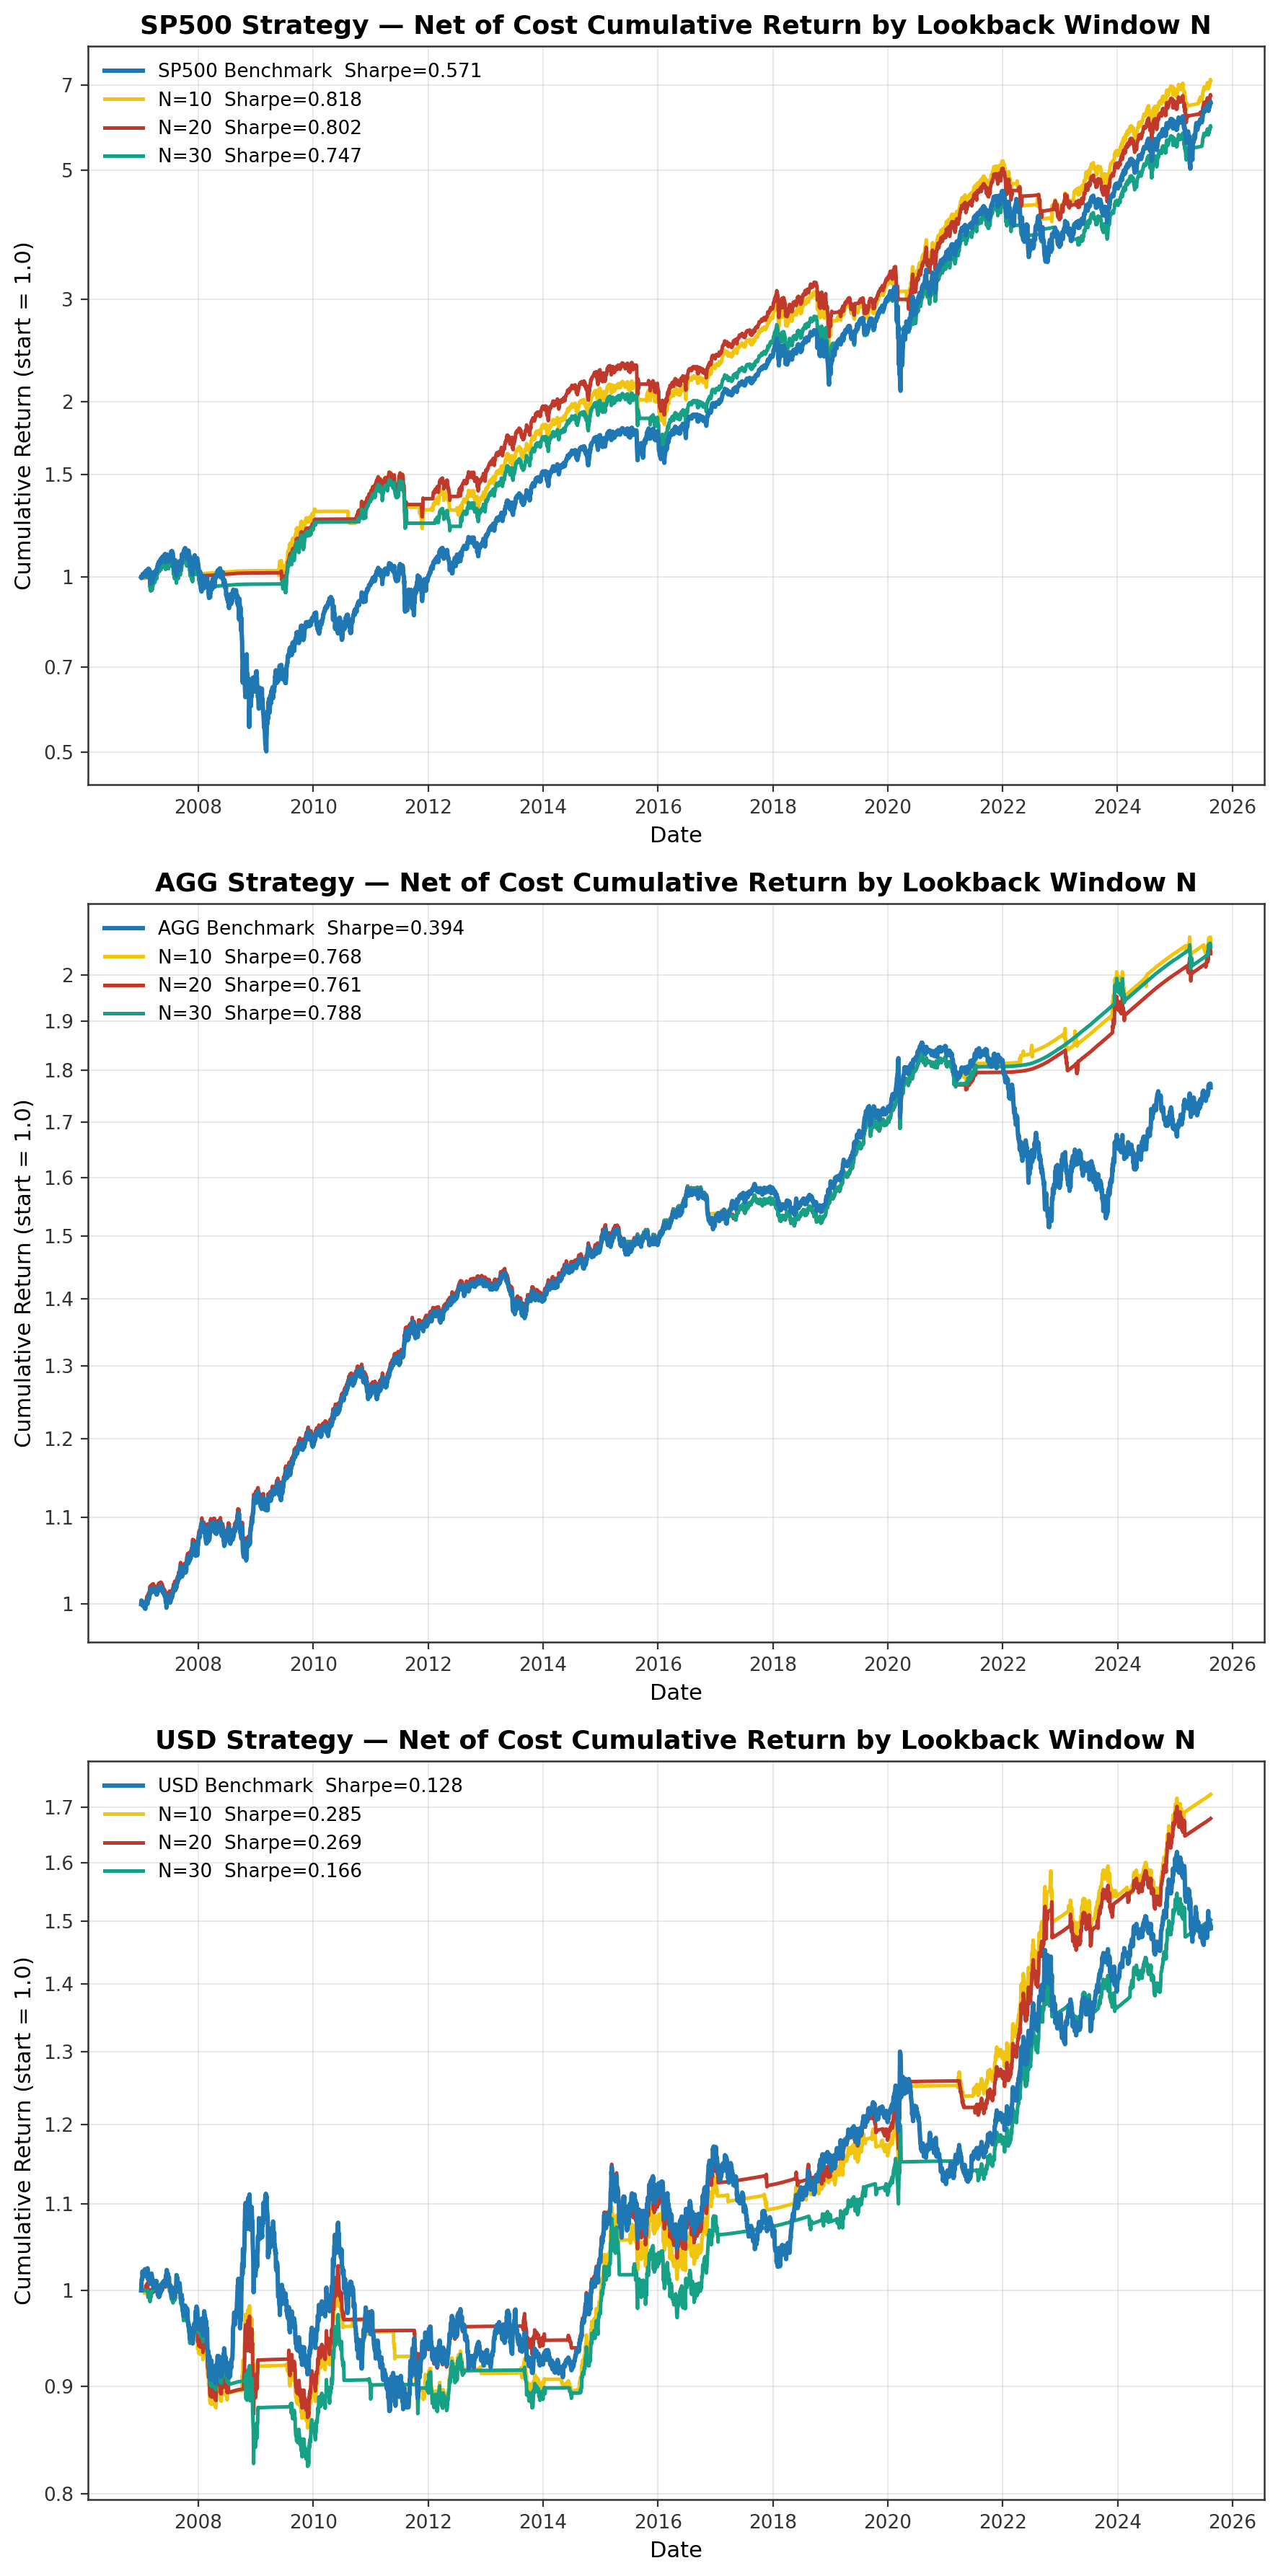

In [18]:
fig, axes = plt.subplots(3, 1, figsize=(9, 18))

ax = axes[0]
_bd, _br, _brf = own_benchmark('SP500')
ax.plot(_bd, (1 + _br.fillna(0)).cumprod(), label=f'SP500 Benchmark  Sharpe={sharpe_ratio(_br, _brf):.3f}',
        color=PALETTE['benchmark'], linewidth=2.2, zorder=10)
for lb in lookback_list:
    if lb == 1:
        continue
    c = PALETTE['lookback'][lb]
    row = lookback_summary_df.loc[lb]
    ax.plot(lb_series[lb]['spx_dt'], lb_series[lb]['spx_cum'],
            label=f'{lookback_name(lb)}  Sharpe={row["SP500 Sharpe"]:.3f}', color=c, linewidth=1.8)
ax.set_title('SP500 Strategy — Net of Cost Cumulative Return by Lookback Window N')
ax.set_xlabel('Date'); ax.set_ylabel('Cumulative Return (start = 1.0)')
log_wealth_axis(ax)
ax.legend(loc='upper left')

ax = axes[1]
_bd, _br, _brf = own_benchmark('BOND')
ax.plot(_bd, (1 + _br.fillna(0)).cumprod(), label=f'AGG Benchmark  Sharpe={sharpe_ratio(_br, _brf):.3f}',
        color=PALETTE['benchmark'], linewidth=2.2, zorder=10)
for lb in lookback_list:
    if lb == 1:
        continue
    c = PALETTE['lookback'][lb]
    row = lookback_summary_df.loc[lb]
    ax.plot(lb_series[lb]['bond_dt'], lb_series[lb]['bond_cum'],
            label=f'{lookback_name(lb)}  Sharpe={row["BOND Sharpe"]:.3f}', color=c, linewidth=1.8)
ax.set_title('AGG Strategy — Net of Cost Cumulative Return by Lookback Window N')
ax.set_xlabel('Date'); ax.set_ylabel('Cumulative Return (start = 1.0)')
log_wealth_axis(ax)
ax.legend(loc='upper left')

ax = axes[2]
_bd, _br, _brf = own_benchmark('USD')
ax.plot(_bd, (1 + _br.fillna(0)).cumprod(), label=f'USD Benchmark  Sharpe={sharpe_ratio(_br, _brf):.3f}',
        color=PALETTE['benchmark'], linewidth=2.2, zorder=10)
for lb in lookback_list:
    if lb == 1:
        continue
    c = PALETTE['lookback'][lb]
    row = lookback_summary_df.loc[lb]
    ax.plot(lb_series[lb]['usd_dt'], lb_series[lb]['usd_cum'],
            label=f'{lookback_name(lb)}  Sharpe={row["USD Sharpe"]:.3f}', color=c, linewidth=1.8)
ax.set_title('USD Strategy — Net of Cost Cumulative Return by Lookback Window N')
ax.set_xlabel('Date'); ax.set_ylabel('Cumulative Return (start = 1.0)')
log_wealth_axis(ax)
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(FIG_DIR + 'lb_single_asset.png', dpi=200, bbox_inches='tight')
plt.show()


## Figure: EW and IVW portfolios by lookback window (`lb_multi_asset.png`)


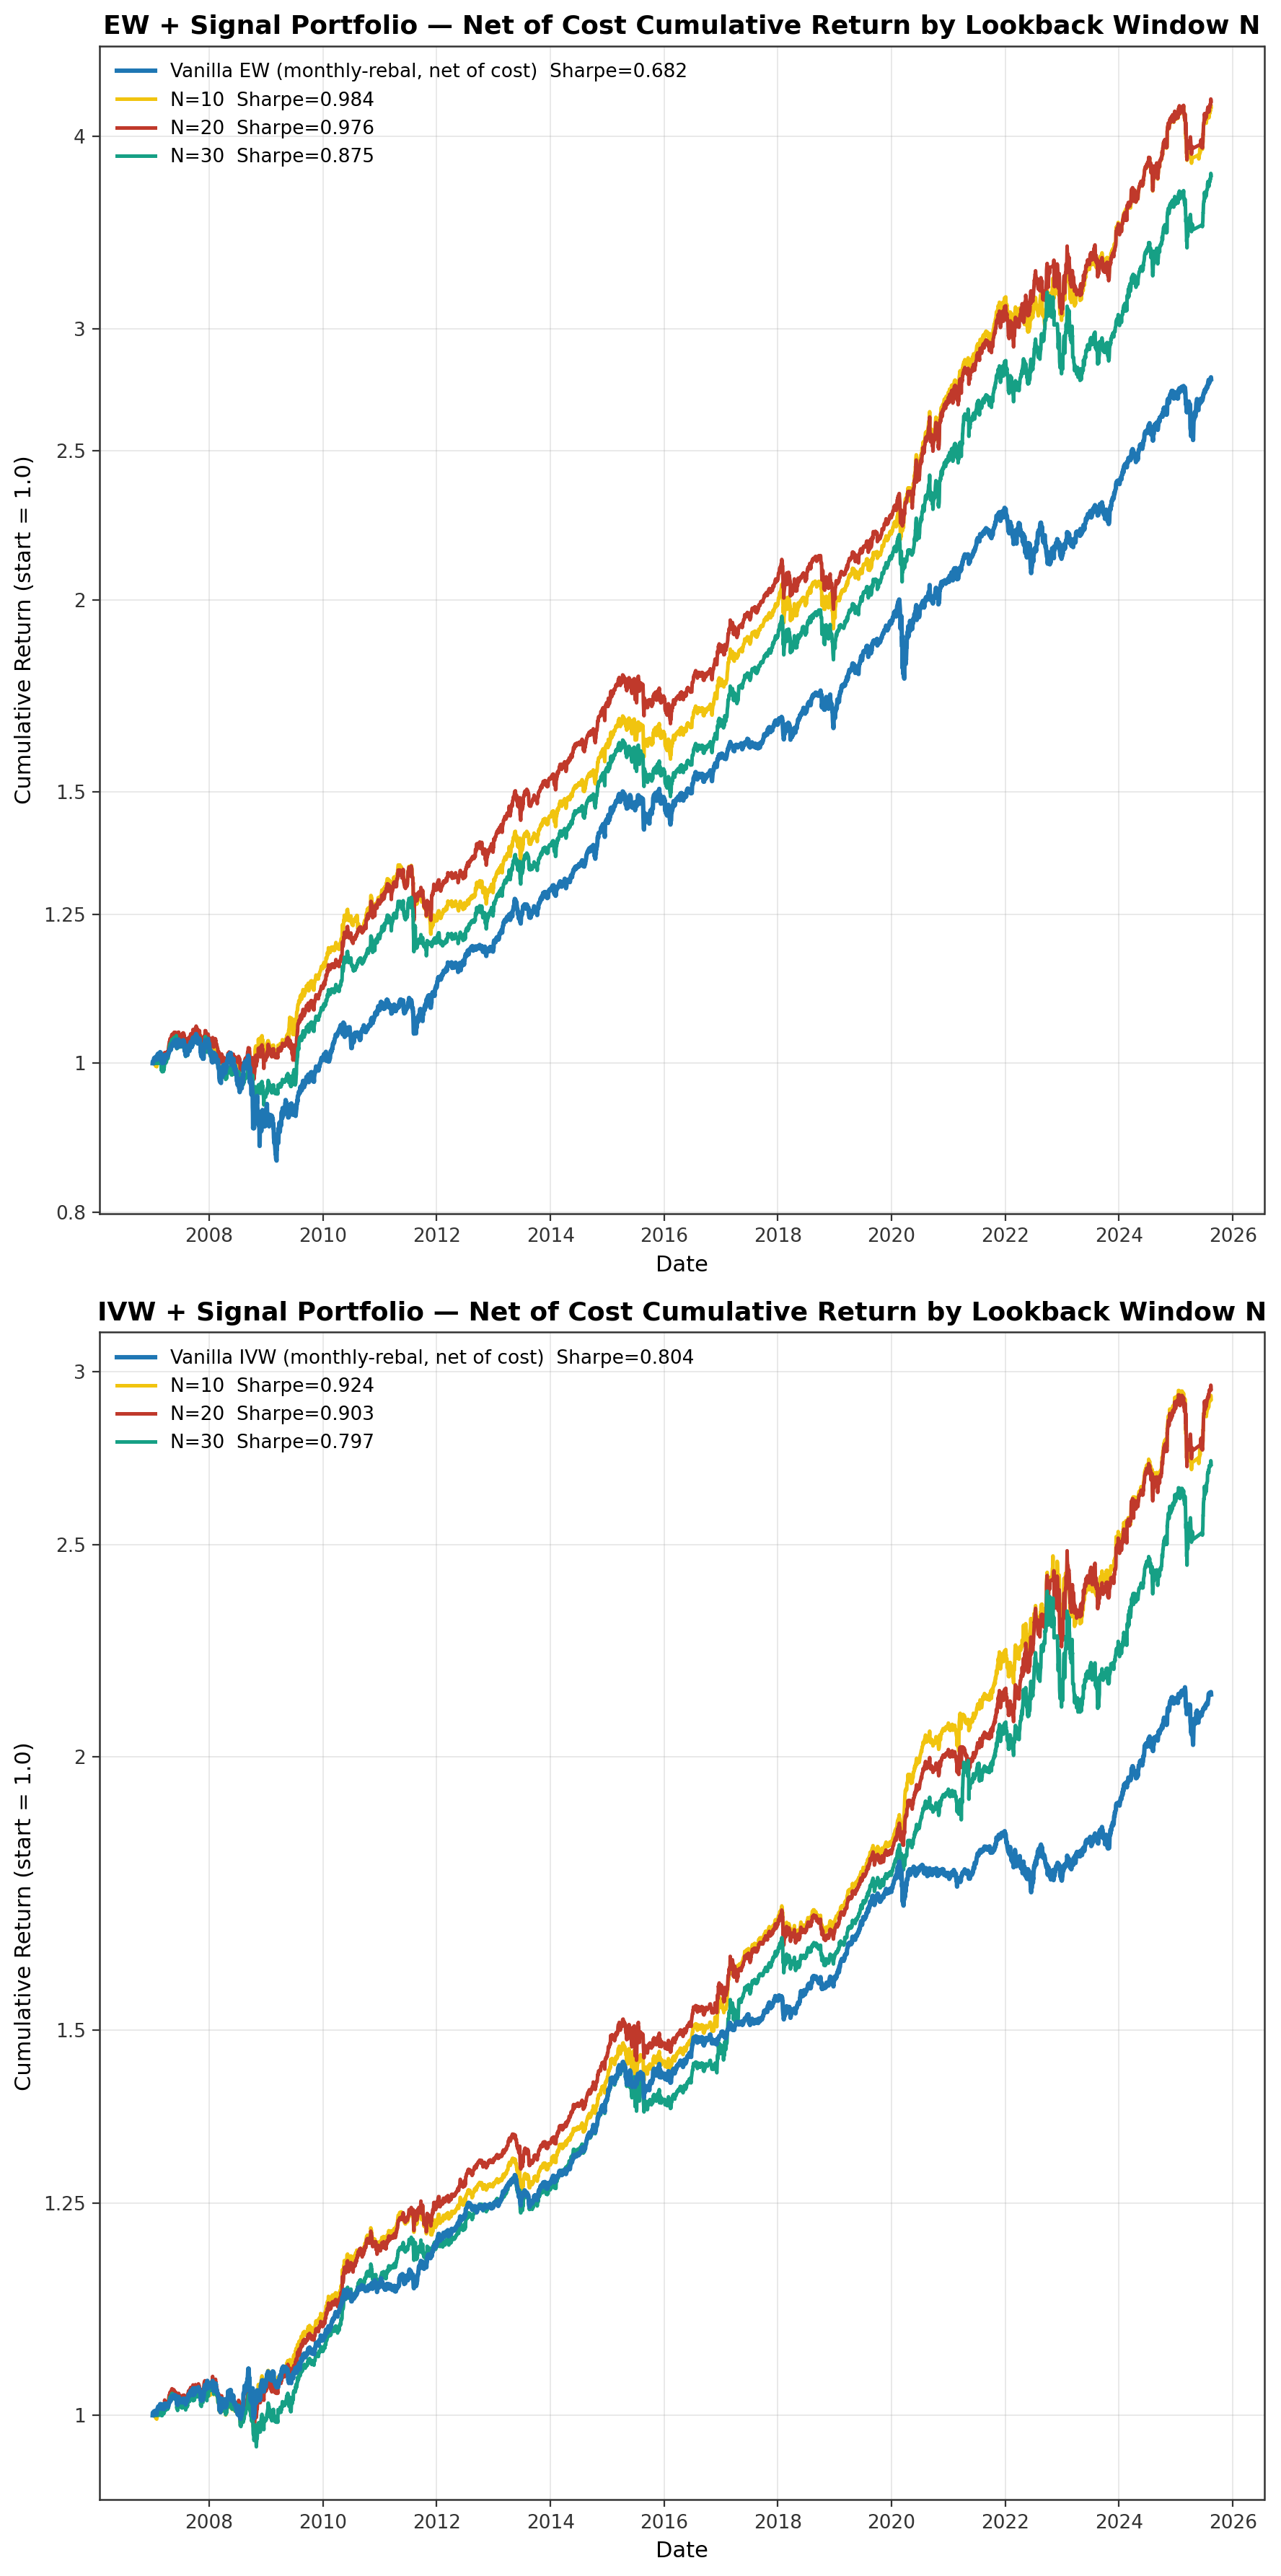

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(9, 18))

ax = axes[0]
ax.plot(df['DateTime'], df['EW_CumRet'], label=f'Vanilla EW (monthly-rebal, net of cost)  Sharpe={ew_sr:.3f}',
        color=PALETTE['benchmark'], linewidth=2.2, zorder=10)
for lb in lookback_list:
    if lb == 1:
        continue
    c = PALETTE['lookback'][lb]
    row = lookback_summary_df.loc[lb]
    ax.plot(df['DateTime'], lb_series[lb]['port_cum'],
            label=f'{lookback_name(lb)}  Sharpe={row["EW+Sig Sharpe"]:.3f}', color=c, linewidth=1.8)
ax.set_title('EW + Signal Portfolio — Net of Cost Cumulative Return by Lookback Window N')
ax.set_xlabel('Date'); ax.set_ylabel('Cumulative Return (start = 1.0)')
log_wealth_axis(ax)
ax.legend(loc='upper left')

ax = axes[1]
ax.plot(df['DateTime'], df['RP_CumRet_nosig'], label=f'Vanilla IVW (monthly-rebal, net of cost)  Sharpe={rp_nosig_sr:.3f}',
        color=PALETTE['benchmark'], linewidth=2.2, zorder=10)
for lb in lookback_list:
    if lb == 1:
        continue
    c = PALETTE['lookback'][lb]
    row = lookback_summary_df.loc[lb]
    ax.plot(df['DateTime'], lb_series[lb]['rp_cum'],
            label=f'{lookback_name(lb)}  Sharpe={row["IVW Sharpe"]:.3f}', color=c, linewidth=1.8)
ax.set_title('IVW + Signal Portfolio — Net of Cost Cumulative Return by Lookback Window N')
ax.set_xlabel('Date'); ax.set_ylabel('Cumulative Return (start = 1.0)')
log_wealth_axis(ax)
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(FIG_DIR + 'lb_multi_asset.png', dpi=200, bbox_inches='tight')
plt.show()


## Tables

### EW and IVW portfolios vs. SP500 (benchmark on its own trading calendar)

In [20]:
sp_dates, sp_ret, sp_rf = own_benchmark('SP500')
sp_cum = (1 + sp_ret.fillna(0)).cumprod()

columns = [
    ("SP500", sp_ret, sp_cum, sp_rf),
    ("EW Vanilla", df['EW_Return'], df['EW_CumRet'], df['rf_daily']),
    ("EW w/ Regime", df['Portfolio_Return'], df['Portfolio_CumRet'], df['rf_daily']),
    ("IVW Vanilla", df['RP_Return_nosig'], df['RP_CumRet_nosig'], df['rf_daily']),
    ("IVW w/ Regime", df['RP_Return'], df['RP_CumRet'], df['rf_daily']),
]
result_table = pd.DataFrame({
    name: {
        "Annual Return": annualized_return(ret),
        "Annual Volatility": annualized_vol(ret),
        "Sharpe Ratio": sharpe_ratio(ret, rf),
        "Sortino Ratio": sortino_ratio(ret),
        "Max Drawdown": max_drawdown(cum),
        "Skewness": skewness(ret),
    } for name, ret, cum, rf in columns
})
result_table.round(6)

,SP500,EW Vanilla,EW w/ Regime,IVW Vanilla,IVW w/ Regime
Annual Return,0.106275,0.055186,0.080472,0.040626,0.060863
Annual Volatility,0.199989,0.062744,0.065052,0.033191,0.045934
Sharpe Ratio,0.570686,0.681576,1.049179,0.804378,1.033660
Sortino Ratio,0.735489,1.090740,1.563501,1.599071,1.729304
Max Drawdown,-0.552502,-0.172551,-0.127211,-0.062374,-0.077129
Skewness,-0.199780,-0.384492,-0.309116,-0.446412,0.239812


### Rolling one-year performance, EW and IVW

In [21]:
rolling_stats = {}
for name, strat_ret, vanilla_ret in [
    ("EW", df["Portfolio_Return"], df["EW_Return"]),
    ("IVW", df["RP_Return"], df["RP_Return_nosig"]),
]:
    s_strat = rolling_cumret(strat_ret)
    s_vanilla = rolling_cumret(vanilla_ret)
    common_idx = s_strat.index.intersection(s_vanilla.index)
    s_strat, s_vanilla = s_strat.loc[common_idx], s_vanilla.loc[common_idx]
    diff = s_strat - s_vanilla

    win_mask = diff > 0
    lose_mask = diff < 0

    rolling_stats[name] = {
            "% windows strategy > vanilla": (s_strat > s_vanilla).mean(),
        "Avg outperformance when winning": diff[win_mask].mean(),
        "Avg underperformance when losing": diff[lose_mask].mean(),
        "P(negative) - vanilla": (s_vanilla < 0).mean(),
        "P(negative) - strategy": (s_strat < 0).mean(),
        "Change in P(negative)": (s_strat < 0).mean() - (s_vanilla < 0).mean(),
    }

rolling_stats_df = pd.DataFrame(rolling_stats).T
rolling_stats_df

,% windows strategy > vanilla,Avg outperformance when winning,Avg underperformance when losing,P(negative) - vanilla,P(negative) - strategy,Change in P(negative)
EW,0.721698,0.053043,-0.036597,0.141509,0.084906,-0.056604
IVW,0.683962,0.040266,-0.017430,0.084906,0.042453,-0.042453


### Lookback sensitivity: Sharpe ratio and trading-cost breakeven

In [22]:
cost_sweep_fine = np.arange(0, 100.01, 0.5)
ret_df_assets = pd.DataFrame({'SP500': df['SP500_Return'], 'BOND': df['BBG AGG BOND_Return'], 'USD': df['USD_Return']})

def find_breakeven(metric_by_cost, benchmark_value):
    costs = sorted(metric_by_cost.keys())
    prev_c, prev_v = costs[0], metric_by_cost[costs[0]]
    if prev_v < benchmark_value:
        return 0.0
    for c in costs[1:]:
        v = metric_by_cost[c]
        if v < benchmark_value:
            frac = (prev_v - benchmark_value) / (prev_v - v)
            return prev_c + frac * (c - prev_c)
        prev_c, prev_v = c, v
    return np.nan

own_bm = {leg: sharpe_ratio(own_benchmark(leg)[1], own_benchmark(leg)[2]) for leg in ['SP500', 'BOND', 'USD']}

breakeven_rows_full = []
for lb in lookback_list_all:
    spx_pos = smooth_position(df['SP500_Signal_raw'], lb)
    bond_pos = smooth_position(df['BOND_Signal_raw'], lb)
    usd_pos = smooth_position(df['USD_Signal_raw'], lb)


    pos_df = pd.DataFrame({'SP500': spx_pos, 'BOND': bond_pos, 'USD': usd_pos})
    active = pos_df.sum(axis=1).replace(0, np.nan)

    weighted_num = pos_df['SP500'] * ret_df_assets['SP500'] + pos_df['BOND'] * ret_df_assets['BOND'] + pos_df['USD'] * ret_df_assets['USD']
    weighted_ret = weighted_num / active
    port_ret_raw = cash_fill(weighted_ret, active, pos_df, df['rf_daily'])

    w_spx_lb, w_bond_lb, w_usd_lb = rp_weights_for_lookback(spx_pos, bond_pos, usd_pos)
    rp_cash = (active.isna() & pos_df.notna().all(axis=1)).astype(float) * df['rf_daily'].fillna(0)
    rp_ret_raw = (w_spx_lb * df['SP500_Return'] + w_bond_lb * df['BBG AGG BOND_Return'] + w_usd_lb * df['USD_Return']) + rp_cash

    w_ew_spx = (pos_df['SP500'].fillna(0) / active).fillna(0)
    w_ew_bond = (pos_df['BOND'].fillna(0) / active).fillna(0)
    w_ew_usd = (pos_df['USD'].fillna(0) / active).fillna(0)
    total_abs_dw_ew = (
        (w_ew_spx - w_ew_spx.shift(1)).abs().fillna(0)
        + (w_ew_bond - w_ew_bond.shift(1)).abs().fillna(0)
        + (w_ew_usd - w_ew_usd.shift(1)).abs().fillna(0)
    )
    total_abs_dw_rp = (
        (w_spx_lb - w_spx_lb.shift(1)).abs().fillna(0)
        + (w_bond_lb - w_bond_lb.shift(1)).abs().fillna(0)
        + (w_usd_lb - w_usd_lb.shift(1)).abs().fillna(0)
    )

    spx_metric_by_cost, bond_metric_by_cost, usd_metric_by_cost = {}, {}, {}
    ew_sharpe_by_cost, rp_sharpe_by_cost = {}, {}

    for c in cost_sweep_fine:
        cost = c / 10000

        _d, _r, _rf = own_calendar_asset('SP500', lb, c);  spx_metric_by_cost[c] = sharpe_ratio(_r, _rf)
        _d, _r, _rf = own_calendar_asset('BOND', lb, c);   bond_metric_by_cost[c] = sharpe_ratio(_r, _rf)
        _d, _r, _rf = own_calendar_asset('USD', lb, c);    usd_metric_by_cost[c] = sharpe_ratio(_r, _rf)

        cost_drag_ew = total_abs_dw_ew * cost
        cost_drag_rp = total_abs_dw_rp * cost
        ew_sharpe_by_cost[c] = sharpe_ratio(port_ret_raw - cost_drag_ew, df['rf_daily'])
        rp_sharpe_by_cost[c] = sharpe_ratio(rp_ret_raw - cost_drag_rp, df['rf_daily'])

    breakeven_rows_full.append({
        'Lookback': lb,
        'SP500 0/1 (bps)': find_breakeven(spx_metric_by_cost, own_bm['SP500']),
        'AGG 0/1 (bps)': find_breakeven(bond_metric_by_cost, own_bm['BOND']),
        'USD 0/1 (bps)': find_breakeven(usd_metric_by_cost, own_bm['USD']),
        'EW 0/1 (bps)': find_breakeven(ew_sharpe_by_cost, ew_sr),
        'IVW 0/1 (bps)': find_breakeven(rp_sharpe_by_cost, rp_nosig_sr),
    })

breakeven_full_df = pd.DataFrame(breakeven_rows_full).set_index('Lookback')

breakdown = [('SP500 w/ Regime', 'SP500 Sharpe', 'SP500 0/1 (bps)'), ('AGG w/ Regime', 'BOND Sharpe', 'AGG 0/1 (bps)'),
             ('USD w/ Regime', 'USD Sharpe', 'USD 0/1 (bps)'), ('EW w/ Regime', 'EW+Sig Sharpe', 'EW 0/1 (bps)'),
             ('IVW w/ Regime', 'IVW Sharpe', 'IVW 0/1 (bps)')]
rows = {}
for label, sharpe_col, be_col in breakdown:
    rows[(label, 'Sharpe')] = {lookback_name(lb): round(lookback_summary_df.loc[lb, sharpe_col], 3) for lb in lookback_list_all}
    rows[(label, 'Trading Cost Breakeven (bps)')] = {lookback_name(lb): ('>100' if pd.isna(breakeven_full_df.loc[lb, be_col]) else round(breakeven_full_df.loc[lb, be_col], 1))
                                                    for lb in lookback_list_all}
lookback_sensitivity = pd.DataFrame(rows).T
lookback_sensitivity

Main result   N=10   N=20   N=30
SP500 w/ Regime Sharpe                             0.848  0.818  0.802  0.747
                Trading Cost Breakeven (bps)        >100   >100   >100   >100
AGG w/ Regime   Sharpe                             0.705  0.768  0.761  0.788
                Trading Cost Breakeven (bps)        69.7   90.7   >100   >100
USD w/ Regime   Sharpe                             0.314  0.285  0.269  0.166
                Trading Cost Breakeven (bps)        31.2   26.8   30.2   10.8
EW w/ Regime    Sharpe                             1.049  0.984  0.976  0.875
                Trading Cost Breakeven (bps)        46.0   39.0   46.6   38.6
IVW w/ Regime   Sharpe                             1.034  0.924  0.903  0.797
                Trading Cost Breakeven (bps)        22.4   14.3   14.8    3.7

### Holding-period distribution (trading days) by asset and lookback

In [23]:
def holding_periods(pos):
    p = pos.dropna()
    if len(p) == 0:
        return []
    return p.groupby(p.ne(p.shift(1)).cumsum()).size().tolist()

def round_half_up(x):
    return int(np.floor(x + 0.5))

def own_calendar_position(leg, lb):
    frame, _, raw_col = _OWN[leg]
    f = frame[frame['DateTime'] <= pd.Timestamp('2025-08-15')].reset_index(drop=True)
    main = hold_until_n(f[raw_col], SMOOTH_N)
    if lb == 1:
        return main
    share = main.rolling(lb).mean()
    return (share >= LOOKBACK_THRESH - 1e-12).astype(float).where(share.notna())

holding_rows = {}
for label, leg in [('SP500', 'SP500'), ('AGG', 'BOND'), ('USD', 'USD')]:
    for stat, q in [('P25', 0.25), ('Median', 0.5), ('P75', 0.75)]:
        holding_rows[(label, stat)] = {
            lookback_name(lb): round_half_up(pd.Series(holding_periods(own_calendar_position(leg, lb))).quantile(q))
            for lb in lookback_list_all
        }
holding_table = pd.DataFrame(holding_rows).T
holding_table

Main result  N=10  N=20  N=30
SP500 P25              26    24    36    42
      Median           55    55    66    71
      P75             174   169   178   232
AGG   P25              15    16    31    45
      Median           31    41    51    68
      P75              64   115   218   322
USD   P25              14    16    20    33
      Median           30    32    59    71
      P75              93   102   124   136

### Graduated tactical tilt: Sharpe ratio by maximum deviation from the anchor and lookback

In [24]:
legs = ['SP500', 'BOND', 'USD']
anchor_ew = pd.DataFrame(1.0 / 3, index=df.index, columns=legs)
anchor_rp = anchor_rp_monthly[legs]

tilt_ret_cols = {'SP500': df['SP500_Return'], 'BOND': df['BBG AGG BOND_Return'], 'USD': df['USD_Return']}
tilt_cost_cols = {leg: cost_bps_map[leg.replace('BOND', 'BOND')] / 10000 for leg in legs}

def tactical_tilt_weights(anchor_df, pos_df, tilt, redistribute):
    """anchor_df: per-day SAA/IVW anchor weights (rows sum to 1). pos_df: 1=bullish,
    0=bearish, NaN=undefined regime position, same legs/index as anchor_df.
    `tilt` is a MAXIMUM DEVIATION from the anchor, applied to every risky weight: a bearish leg is cut by
    `tilt` (floored so it can't go negative if its anchor weight is smaller than `tilt`); the freed pool is shared
    across that day's bullish legs -- 'equal' splits it evenly (EW), 'proportional' by each bullish leg's own
    anchor-weight share (IVW) -- but no bullish leg may gain more than `tilt`. Whatever cannot be placed (e.g. two
    bearish legs free 2*tilt but the single bullish leg can only take `tilt`; or an all-bearish day) is left in cash,
    which earns the T-bill rate -- weights are never renormalized back to 1, so there is no leverage.
    Hence every risky weight stays within +/- `tilt` of its anchor. tilt = 100% imposes no cap and is the 0/1 rule."""
    is_bear = (pos_df == 0)
    is_bull = (pos_df == 1)
    is_defined = pos_df.notna()

    cut = anchor_df.where(is_bear, 0.0).clip(upper=tilt)
    pool = cut.sum(axis=1)
    n_bull = is_bull.sum(axis=1)
    bull_anchor_sum = anchor_df.where(is_bull, 0.0).sum(axis=1)

    weights = {}
    for leg in anchor_df.columns:
        w = anchor_df[leg].copy()
        w[is_bear[leg]] = anchor_df[leg][is_bear[leg]] - cut[leg][is_bear[leg]]
        if redistribute == 'equal':
            share = (pool / n_bull.replace(0, np.nan)).fillna(0)
        elif redistribute == 'proportional':
            share = (pool * anchor_df[leg] / bull_anchor_sum.replace(0, np.nan)).fillna(0)
        else:
            raise ValueError(redistribute)
        share = share.clip(upper=tilt)
        w[is_bull[leg]] = anchor_df[leg][is_bull[leg]] + share[is_bull[leg]]
        w[~is_defined[leg]] = np.nan
        weights[leg] = w
    return pd.DataFrame(weights)

def run_tilt_strategy(anchor_df, tilt, lb, redistribute):
    pos_df = pd.DataFrame({
        'SP500': smooth_position(df['SP500_Signal_raw'], lb),
        'BOND': smooth_position(df['BOND_Signal_raw'], lb),
        'USD': smooth_position(df['USD_Signal_raw'], lb),
    })

    w = tactical_tilt_weights(anchor_df, pos_df, tilt, redistribute)

    cash_w = 1.0 - sum(w[leg] for leg in legs)
    port_ret_raw = sum(w[leg] * tilt_ret_cols[leg] for leg in legs) + cash_w * df['rf_daily']
    cost_drag = sum((w[leg] - w[leg].shift(1)).abs().fillna(0) * tilt_cost_cols[leg] for leg in legs)
    port_ret = port_ret_raw - cost_drag

    port_cum = (1 + port_ret.fillna(0)).cumprod()
    return {
        'Sharpe': sharpe_ratio(port_ret, df['rf_daily']),
        'Sortino': sortino_ratio(port_ret),
        'AnnRet': annualized_return(port_ret),
        'AnnVol': annualized_vol(port_ret),
        'MaxDD': max_drawdown(port_cum),
        'Returns': port_ret,
        'Returns_cash0': port_ret - cash_w * df['rf_daily'],
    }

In [25]:
lb_list_tilt = [1, 20, 30]
tilt_list = [0.05, 0.10, 0.15, 0.20]

tilt_results = {}
for name, anchor_df, mode in [('EW', anchor_ew, 'equal'), ('IVW', anchor_rp, 'proportional')]:
    for lb in lb_list_tilt:
        for t in tilt_list:
            tilt_results[(name, lb, f'{int(t*100)}%')] = run_tilt_strategy(anchor_df, t, lb, mode)

tilt_cols = [f'{int(t*100)}%' for t in tilt_list] + ['0/1 (tau=100%)']
sharpe_01 = {'EW': 'EW+Sig Sharpe', 'IVW': 'IVW Sharpe'}
tilt_sharpe_tables = {}
for name in ['EW', 'IVW']:
    tbl = pd.DataFrame(index=[lookback_name(lb) for lb in lb_list_tilt], columns=tilt_cols, dtype=float)
    for lb in lb_list_tilt:
        for c in tilt_cols:
            if c == '0/1 (tau=100%)':
                tbl.loc[lookback_name(lb), c] = lookback_summary_df.loc[lb, sharpe_01[name]]
            else:
                tbl.loc[lookback_name(lb), c] = tilt_results[(name, lb, c)]['Sharpe']
    tilt_sharpe_tables[name] = tbl.round(3)
print('Vanilla EW Sharpe:', round(ew_sr, 3), '| Vanilla IVW Sharpe:', round(rp_nosig_sr, 3))
tilt_sharpe_tables['EW']

Vanilla EW Sharpe: 0.682 | Vanilla IVW Sharpe: 0.804


,5%,10%,15%,20%,0/1 (tau=100%)
Main result,0.789,0.884,0.967,1.029,1.049
N=20,0.785,0.876,0.953,1.009,0.976
N=30,0.768,0.842,0.903,0.942,0.875


In [26]:
tilt_sharpe_tables['IVW']

,5%,10%,15%,20%,0/1 (tau=100%)
Main result,0.906,0.976,1.025,1.058,1.034
N=20,0.898,0.955,0.992,1.014,0.903
N=30,0.866,0.895,0.914,0.928,0.797


### Sensitivity to the cash assumption: EW and IVW portfolios with regime signal

In [27]:
pairs = [('EW', df['Portfolio_Return'], df['Portfolio_Return_cash0']),
         ('IVW', df['RP_Return'], df['RP_Return_cash0'])]
cash_rows = {}
for name, r_tbill, r_zero in pairs:
    for tag, r in [('Cash = T-bill', r_tbill), ('Cash = 0', r_zero)]:
        cash_rows[(name, tag)] = {
            'Annual Return': annualized_return(r), 'Annual Volatility': annualized_vol(r),
            'Sharpe Ratio': sharpe_ratio(r, df['rf_daily']), 'Sortino Ratio': sortino_ratio(r),
            'Max Drawdown': max_drawdown((1 + r.fillna(0)).cumprod()), 'Skewness': skewness(r),
        }
cash_table = pd.DataFrame(cash_rows)
cash_table.round(6)

EW                     IVW          
                  Cash = T-bill  Cash = 0 Cash = T-bill  Cash = 0
Annual Return          0.080472  0.080182      0.060863  0.060578
Annual Volatility      0.065052  0.065054      0.045934  0.045935
Sharpe Ratio           1.049179  1.044699      1.033660  1.027434
Sortino Ratio          1.563501  1.558286      1.729304  1.721663
Max Drawdown          -0.127211 -0.127211     -0.077129 -0.081012
Skewness              -0.309116 -0.308325      0.239812  0.240892